<a href="https://colab.research.google.com/github/heloisafrancops-collab/Inteligencia-Artificial1/blob/main/Atividade_DataSet_Helo%C3%ADsa_Franco_6D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset 1 — Students Performance in Exams

Nosso objetivo será treinar seis modelos de classificação para prever se o estudante terá desempenho abaixo de 60 pontos ou igual/superior a 60 pontos, utilizando as informações pessoais e de preparação disponíveis.

Importante: essa classificação será criada por nós para praticar os algoritmos. A base original contém notas, não essa classificação pronta. Para evitar que o modelo veja a resposta antes de prever, as notas serão usadas para criar a categoria, mas não serão utilizadas como características de entrada.

# Passo 1 — Importação das bibliotecas
Explicação: as bibliotecas são ferramentas prontas. O pandas lê a tabela, o sklearn treina e avalia os modelos, e o matplotlib cria os gráficos.

In [161]:

# Biblioteca para organizar os dados
import pandas as pd

# Biblioteca para criar gráficos
import matplotlib.pyplot as plt

# Ferramenta para separar os dados em treino e teste
from sklearn.model_selection import train_test_split, GridSearchCV

# Ferramentas para padronizar os dados e criar o Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliar os resultados
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay


# Passo 2 — Carregamento do dataset
Explicação: vamos carregar o arquivo CSV que você baixou do Kaggle. No Google Colab, o código abrirá uma janela para você selecionar o arquivo no computador.

In [162]:

# Instala a biblioteca para baixar datasets do Kaggle
!pip install -q kagglehub

# Importa as bibliotecas necessárias
import kagglehub
import os
import pandas as pd

# Baixa o dataset
path = kagglehub.dataset_download(
    "spscientist/students-performance-in-exams"
)

# Procura o arquivo CSV na pasta baixada
for arquivo in os.listdir(path):
    if arquivo.endswith(".csv"):
        nome_arquivo = os.path.join(path, arquivo)

        # Carrega o arquivo no DataFrame
        df = pd.read_csv(nome_arquivo)
        break

# Mostra as cinco primeiras linhas
df.head()


Using Colab cache for faster access to the 'students-performance-in-exams' dataset.


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


# Passo 3 — Conhecendo os dados
Explicação: antes de treinar, precisamos entender como a tabela está organizada, quais são as colunas, quantas linhas existem e se há valores vazios.

In [163]:

# Mostra a quantidade de linhas e colunas
print("Tamanho do dataset:", df.shape)

# Mostra os nomes das colunas
print("\nColunas:")
print(df.columns)

# Mostra os tipos de dados e informações gerais
print("\nInformações:")
df.info()

# Verifica se existem valores vazios
print("\nValores vazios:")
print(df.isnull().sum())


Tamanho do dataset: (1000, 8)

Colunas:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Valores vazios:
gender          

# Passo 4 — Preparar os dados para a classificação
Explicação: O dataset possui notas de matemática, leitura e escrita. Vamos calcular a média e criar duas classes: 0 para média abaixo de 60 e 1 para média igual ou superior a 60.

Usaremos apenas as informações categóricas como entrada dos modelos. Assim, as notas usadas para criar a classificação não serão usadas para prever essa mesma classificação.

In [164]:

# Calcula a média das três notas
df["Media"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

# Cria a classificação de desempenho
# 0 = média abaixo de 60
# 1 = média igual ou acima de 60
df["Desempenho"] = (df["Media"] >= 60).astype(int)

# Seleciona as informações que serão usadas para fazer previsões
X = df[
    [
        "gender",
        "race/ethnicity",
        "parental level of education",
        "lunch",
        "test preparation course"
    ]
]

# Define a coluna que queremos prever
y = df["Desempenho"]

# Transforma os textos em colunas numéricas
X = pd.get_dummies(X, drop_first=True)

# Mostra as primeiras linhas das entradas
print("Dados de entrada:")
display(X.head())

# Mostra a quantidade de pessoas em cada classe
print("\nQuantidade por classe:")
print(y.value_counts())


Dados de entrada:


,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,False,True,False,False,False,True,False,False,False,False,True,True
1,False,False,True,False,False,False,False,False,True,False,True,False
2,False,True,False,False,False,False,False,True,False,False,True,True
3,True,False,False,False,False,False,False,False,False,False,False,True
4,True,False,True,False,False,False,False,False,True,False,True,True



Quantidade por classe:
Desempenho
1    715
0    285
Name: count, dtype: int64


# Passo 4.1 — Análise exploratória dos dados
Nesta etapa, vou explorar visualmente o dataset para entender melhor a distribuição das médias das notas dos estudantes. Para isso, vou utilizar um histograma que mostra a quantidade de estudantes em cada intervalo de média. Essa análise ajuda a conhecer melhor os dados antes de avaliar os resultados dos modelos de classificação.

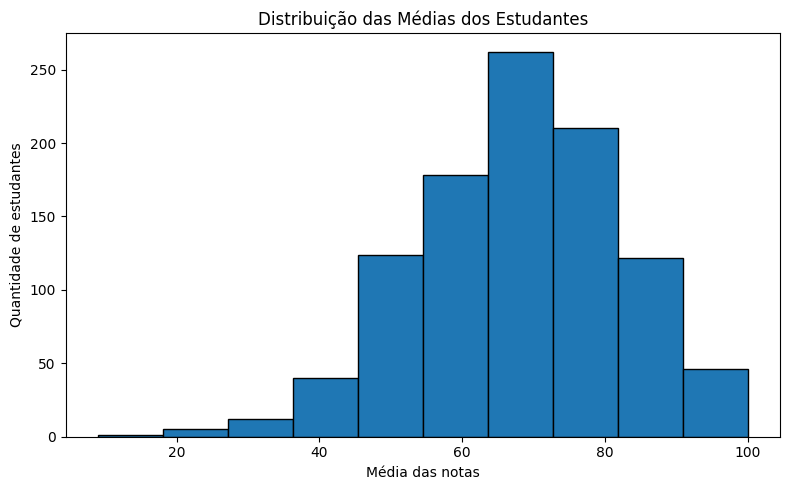

In [165]:

# Calcula a média das notas de cada estudante
df["Media"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

# Cria o histograma da distribuição das médias
plt.figure(figsize=(8, 5))

plt.hist(
    df["Media"],
    bins=10,
    edgecolor="black"
)

# Adiciona o título e os nomes dos eixos
plt.title("Distribuição das Médias dos Estudantes")
plt.xlabel("Média das notas")
plt.ylabel("Quantidade de estudantes")

# Ajusta o espaço do gráfico
plt.tight_layout()

# Exibe o gráfico
plt.show()


# Passo 5 — Divisão entre treino e teste
Explicação: separamos os dados em dois grupos. O modelo aprende com 80% dos registros e é avaliado com os outros 20%, que não foram usados no treinamento.
- X: informações usadas para prever.
- y: resposta correta que queremos prever.
- random_state=42: mantém a mesma divisão quando executamos novamente.
- stratify=y: tenta manter a proporção das categorias nos dois grupo

In [166]:

# Separa os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Mostra a quantidade de dados em cada parte
print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)


Dados de treino: (800, 12)
Dados de teste: (200, 12)


# Passo 6 — Treinar os modelos e otimizar o SVM
Explicação: Nesta etapa, vou treinar seis modelos de classificação: SVM Linear, SVM Pipeline, SVM Otimizado, Árvore de Decisão, Random Forest e Gradient Boosting. Depois, vou comparar os resultados obtidos por cada um.

In [167]:

# Cria o SVM linear com Pipeline
# O Pipeline padroniza os dados antes de treinar o SVM
svm_linear = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

# Cria o SVM com Pipeline para testar diferentes parâmetros
svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC()
)

# Define as combinações de parâmetros que serão testadas
parametros = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Configura a otimização com validação cruzada de 5 partes
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parametros,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Cria os outros modelos
modelos = {
    "SVM Linear": svm_linear,

    "SVM Pipeline": make_pipeline(
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_search,

    "Árvore de Decisão": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Guarda as previsões de cada modelo
previsoes = {}

# Treina cada modelo e faz as previsões
for nome, modelo in modelos.items():

    print("Treinando:", nome)

    # Treina o modelo com os dados de treino
    modelo.fit(X_treino, y_treino)

    # Faz as previsões com os dados de teste
    previsoes[nome] = modelo.predict(X_teste)

# Mostra os melhores parâmetros encontrados pelo GridSearchCV
print("\nMelhores parâmetros do SVM otimizado:")
print(grid_search.best_params_)

# Mostra a melhor acurácia média na validação cruzada
print("\nMelhor acurácia na validação cruzada:")
print(grid_search.best_score_)


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM otimizado:
{'svc__C': 10, 'svc__kernel': 'linear'}

Melhor acurácia na validação cruzada:
0.7550000000000001


# Passo 7 — Avaliar a acurácia e visualizar os resultados
Explicação: Vamos comparar a acurácia dos seis modelos, consultar o relatório de classificação e visualizar as matrizes de confusão. A acurácia mede a proporção total de previsões corretas; a matriz de confusão mostra os acertos e erros de cada classe.


Modelo: SVM Linear
Acurácia: 68.5 %
              precision    recall  f1-score   support

           0       0.38      0.18      0.24        57
           1       0.73      0.89      0.80       143

    accuracy                           0.69       200
   macro avg       0.56      0.53      0.52       200
weighted avg       0.63      0.69      0.64       200


Modelo: SVM Pipeline
Acurácia: 68.0 %
              precision    recall  f1-score   support

           0       0.37      0.18      0.24        57
           1       0.73      0.88      0.80       143

    accuracy                           0.68       200
   macro avg       0.55      0.53      0.52       200
weighted avg       0.63      0.68      0.64       200


Modelo: SVM Otimizado
Acurácia: 65.5 %
              precision    recall  f1-score   support

           0       0.27      0.12      0.17        57
           1       0.71      0.87      0.78       143

    accuracy                           0.66       200
   macro avg

,Modelo,Acurácia
3,Árvore de Decisão,0.720
4,Random Forest,0.710
0,SVM Linear,0.685
1,SVM Pipeline,0.680
5,Gradient Boosting,0.680
2,SVM Otimizado,0.655


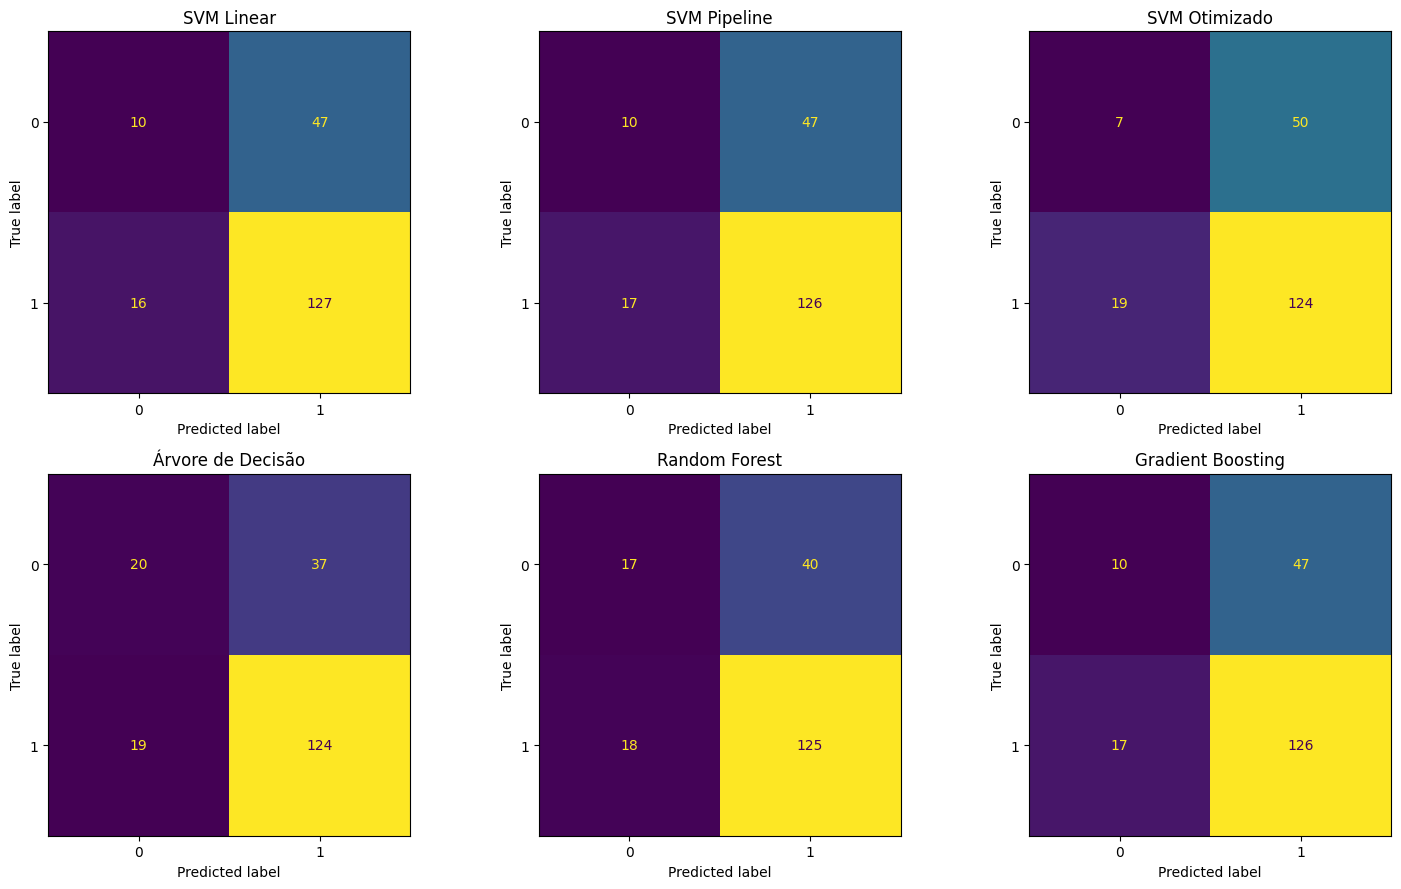

In [168]:

# Cria uma lista para guardar as acurácias
resultados = []

# Avalia cada modelo treinado
for nome, previsao in previsoes.items():

    # Calcula a acurácia usando os dados de teste
    acuracia = accuracy_score(y_teste, previsao)

    # Guarda o nome e a acurácia do modelo
    resultados.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    # Mostra o relatório de classificação
    print("\nModelo:", nome)
    print("Acurácia:", round(100 * acuracia, 2), "%")

    print(
        classification_report(
            y_teste,
            previsao,
            zero_division=0
        )
    )

# Organiza os resultados da maior para a menor acurácia
comparacao = pd.DataFrame(resultados)
comparacao = comparacao.sort_values(
    by="Acurácia",
    ascending=False
)

# Mostra a comparação entre os modelos
print("\nComparação das acurácias:")
display(comparacao)

# Cria uma figura com espaço para seis matrizes de confusão
fig, eixos = plt.subplots(2, 3, figsize=(15, 9))

# Percorre os modelos e desenha suas matrizes de confusão
for eixo, (nome, previsao) in zip(eixos.flatten(), previsoes.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        previsao,
        ax=eixo,
        colorbar=False
    )

    # Coloca o nome do modelo no gráfico
    eixo.set_title(nome)

# Ajusta o espaço entre os gráficos
plt.tight_layout()

# Exibe as matrizes de confusão
plt.show()


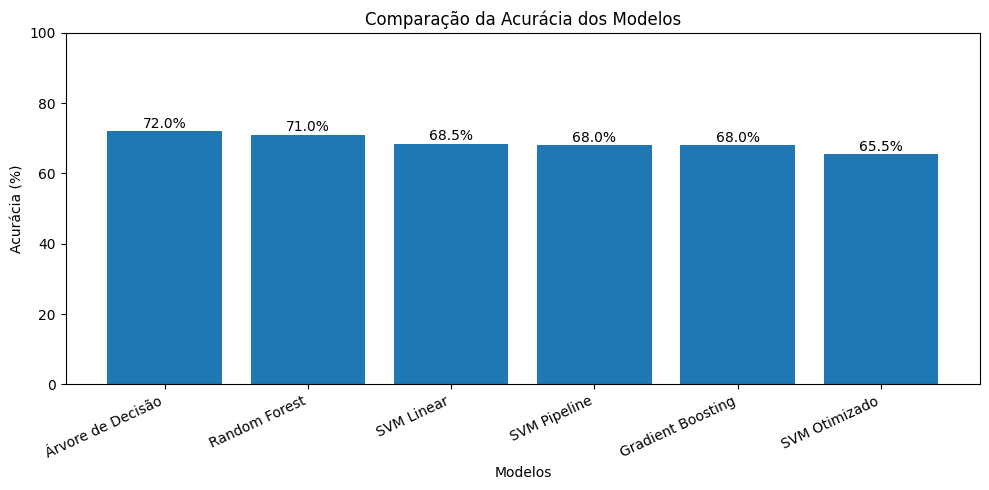

In [169]:

# Cria o gráfico de barras para comparar os modelos
plt.figure(figsize=(10, 5))

# Mostra a acurácia de cada modelo em porcentagem
plt.bar(
    comparacao["Modelo"],
    comparacao["Acurácia"] * 100
)

# Adiciona o título e os nomes dos eixos
plt.title("Comparação da Acurácia dos Modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

# Mostra os nomes dos modelos inclinados para facilitar a leitura
plt.xticks(rotation=25, ha="right")

# Define o limite do eixo vertical
plt.ylim(0, 100)

# Escreve a porcentagem em cima de cada barra
for i, valor in enumerate(comparacao["Acurácia"] * 100):
    plt.text(i, valor + 1, f"{valor:.1f}%", ha="center")

# Ajusta o espaço do gráfico
plt.tight_layout()

# Exibe o gráfico
plt.show()


**Gráfico de comparação da acurácia dos modelos**

Neste gráfico, comparo a acurácia dos seis modelos de classificação utilizados. As barras mostram a porcentagem de previsões corretas de cada modelo, facilitando a visualização dos resultados. Assim, consigo identificar qual modelo apresentou o melhor desempenho no conjunto de teste.

# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.631,0.685,0.642
1,SVM Pipeline,0.626,0.680,0.638
2,SVM Otimizado,0.586,0.655,0.607
3,Árvore de Decisão,0.697,0.720,0.702
4,Random Forest,0.680,0.710,0.686
5,Gradient Boosting,0.626,0.680,0.638


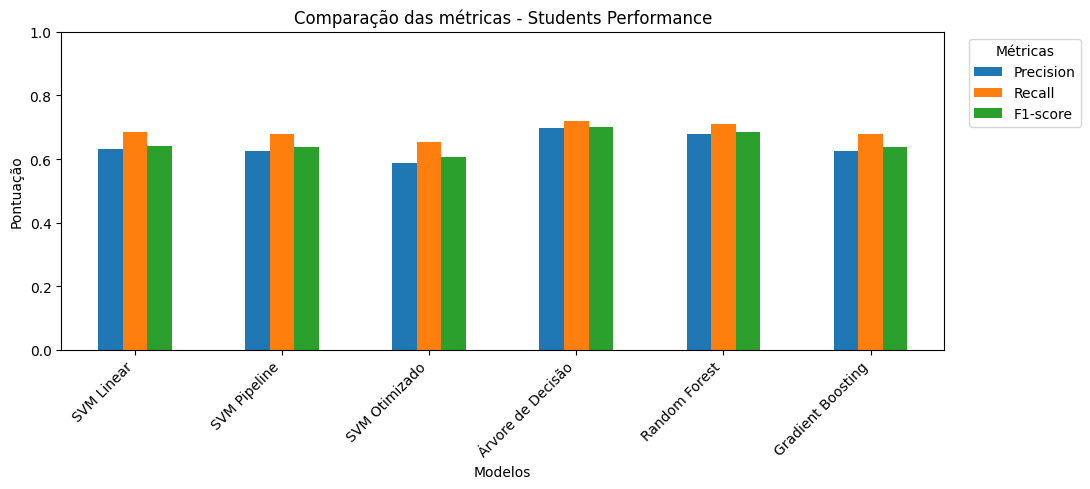

<Figure size 640x480 with 0 Axes>

In [170]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# Calcula as métricas dos seis modelos
metricas_estudantes = []

for nome, previsao in previsoes.items():
    metricas_estudantes.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste, previsao, average="weighted", zero_division=0)
    })

# Organiza e apresenta os resultados
df_metricas_estudantes = pd.DataFrame(metricas_estudantes)
display(df_metricas_estudantes.round(3))

# Compara as métricas visualmente
df_metricas_estudantes.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - Students Performance")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Depois de executar os modelos, vamos identificar qual teve a maior acurácia no teste e registrar o que observamos. Como já temos os resultados deste dataset, a conclusão será preenchida com os valores obtidos.

In [171]:
# Identifica o modelo com a maior acurácia no teste
melhor_modelo = comparacao.loc[comparacao["Acurácia"].idxmax()]

# Mostra a conclusão dos resultados
print("CONCLUSÃO")
print()
print("O modelo com a maior acurácia no teste foi:",
      melhor_modelo["Modelo"])
print("Acurácia obtida:", round(melhor_modelo["Acurácia"] * 100, 2), "%")
print()
print("O modelo de Árvore de Decisão apresentou a maior acurácia,")
print("com 72%, seguido pelo Random Forest, com 71%.")
print("Os resultados permitiram comparar os modelos e observar")
print("qual apresentou o melhor desempenho na classificação")
print("do desempenho dos estudantes.")

CONCLUSÃO

O modelo com a maior acurácia no teste foi: Árvore de Decisão
Acurácia obtida: 72.0 %

O modelo de Árvore de Decisão apresentou a maior acurácia,
com 72%, seguido pelo Random Forest, com 71%.
Os resultados permitiram comparar os modelos e observar
qual apresentou o melhor desempenho na classificação
do desempenho dos estudantes.


# Dataset 2 — FISHMORPH
O FISHMORPH contém informações sobre características físicas de peixes de água doce, como tamanho do corpo, formato corporal, posição dos olhos e características das nadadeiras.



Para manter o mesmo estilo de aprendizado de máquina do primeiro projeto, vamos trabalhar com classificação usando características morfológicas. Antes de definir a variável que o modelo vai prever, precisamos conferir os nomes reais das colunas e os valores disponíveis no arquivo, porque esse dataset é diferente do de notas dos estudantes.

# Passo 1 — Importar as bibliotecas
Explicação: Vou importar as bibliotecas para analisar os dados, treinar os seis modelos de classificação, otimizar o SVM e avaliar os resultados.

In [172]:

# Biblioteca para organizar os dados
import pandas as pd

# Bibliotecas para criar gráficos
import matplotlib.pyplot as plt

# Ferramentas para separar os dados e otimizar parâmetros
from sklearn.model_selection import train_test_split, GridSearchCV

# Ferramentas para preparar os dados
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliar os resultados
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay


# Passo 2 — Baixar e carregar o dataset
Explicação: Vou baixar o dataset FISHMORPH do Kaggle e localizar o arquivo CSV que contém os dados dos peixes.

In [173]:

# Instala a biblioteca para baixar datasets do Kaggle
!pip install -q kagglehub

# Importa as bibliotecas necessárias
import kagglehub
import os
import pandas as pd

# Baixa o dataset
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

# Procura os arquivos CSV dentro da pasta baixada
arquivos_csv = []

for pasta, subpastas, arquivos in os.walk(path):
    for arquivo in arquivos:
        if arquivo.endswith(".csv") and "readme" not in arquivo.lower():
            arquivos_csv.append(os.path.join(pasta, arquivo))

# Mostra os arquivos encontrados
print("Arquivos encontrados:", arquivos_csv)

# Carrega o primeiro arquivo CSV encontrado
nome_arquivo = arquivos_csv[0]
df = pd.read_csv(nome_arquivo)

# Mostra as cinco primeiras linhas
df.head()


Using Colab cache for faster access to the 'fishmorph-dataset' dataset.
Arquivos encontrados: ['/kaggle/input/fishmorph-dataset/FISHMORPH_Order_Dataset.csv', '/kaggle/input/fishmorph-dataset/FISHMORPH_Family_Dataset.csv']


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes


# Passo 3 — Conhecer os dados
Explicação: Vou verificar o tamanho do dataset, os nomes das colunas, os tipos de dados e a quantidade de valores ausentes antes de escolher as informações para o modelo.

In [174]:

# Mostra a quantidade de linhas e colunas
print("Tamanho do dataset:", df.shape)

# Mostra os nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

# Mostra os tipos de dados e informações gerais
print("\nInformações do dataset:")
df.info()

# Verifica os valores ausentes
print("\nValores ausentes:")
print(df.isnull().sum())


Tamanho do dataset: (8342, 11)

Colunas:
['MBl', 'BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv', 'PFs', 'CPt', 'Order']

Informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Order   8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB

Valores ausentes:
MBl      0
BEl      0
VEp      0
REs      0
OGp      0
RMl      0
BLs      0
PFv      0
PFs      0
CPt      0
Order    0
dtype: int64


# Passo 4 — Preparar os dados para a classificação
Explicação: Vamos usar as características físicas dos peixes para tentar prever sua ordem taxonômica (Order). Para isso, selecionaremos as medidas morfológicas, converteremos os valores para números e prepararemos as classes para a classificação.

Para que a validação cruzada funcione, vamos considerar as oito ordens mais frequentes entre aquelas que possuem pelo menos dez registros. Isso torna o experimento mais viável e facilita a comparação dos modelos.

Para o treinamento dos modelos, utilizei as nove características físicas disponíveis e selecionadas no dataset. Essas informações serão usadas para prever a ordem taxonômica dos peixes e comparar o desempenho dos seis algoritmos.

In [175]:

# Organiza os nomes das colunas para facilitar a localização
colunas = {coluna.strip().lower(): coluna for coluna in df.columns}

# Define a coluna que queremos prever
coluna_alvo = colunas["order"]

# Lista das características físicas dos peixes
nomes_tracos = [
    "MBI", "BEl", "VEp", "REs", "OGp",
    "RMl", "BLs", "PFv", "PFs", "CPt"
]

# Seleciona as características que existem no dataset
tracos = [
    colunas[nome.lower()]
    for nome in nomes_tracos
    if nome.lower() in colunas
]

# Mostra as características encontradas
print("Características utilizadas:", tracos)

# Copia os dados para preparar a classificação
dados = df[tracos + [coluna_alvo]].copy()

# Transforma as características em valores numéricos
for coluna in tracos:
    dados[coluna] = pd.to_numeric(
        dados[coluna],
        errors="coerce"
    )

# Remove linhas sem a classe que queremos prever
dados = dados.dropna(subset=[coluna_alvo])

# Remove linhas sem nenhuma característica disponível
dados = dados.dropna(subset=tracos, how="all")

# Conta quantos registros existem em cada ordem
contagem = dados[coluna_alvo].value_counts()

# Mantém apenas ordens com pelo menos dez registros
ordens_validas = contagem[contagem >= 10]

# Seleciona as oito ordens mais frequentes
ordens_selecionadas = ordens_validas.head(8).index

# Mantém somente os registros dessas ordens
dados = dados[dados[coluna_alvo].isin(ordens_selecionadas)].copy()

# Define as características de entrada
X = dados[tracos]

# Define a classe que o modelo vai prever
y = dados[coluna_alvo].astype(str)

# Mostra a quantidade de registros por ordem
print("\nQuantidade por ordem:")
print(y.value_counts())

# Mostra as primeiras linhas das características
display(X.head())


Características utilizadas: ['BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv', 'PFs', 'CPt']

Quantidade por ordem:
Order
Cypriniformes         1933
Perciformes           1826
Siluriformes          1800
Characiformes         1281
Cyprinodontiformes     554
Osteoglossiformes      156
Clupeiformes           104
Gymnotiformes          101
Name: count, dtype: int64


,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991
1,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592
2,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580
3,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062
4,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906


# Passo 4.1 — Análise exploratória dos dados
Explicação: Vou criar um histograma para observar a distribuição do tamanho máximo do corpo dos peixes. Esse gráfico ajuda a entender como uma das características físicas está distribuída antes do treinamento.

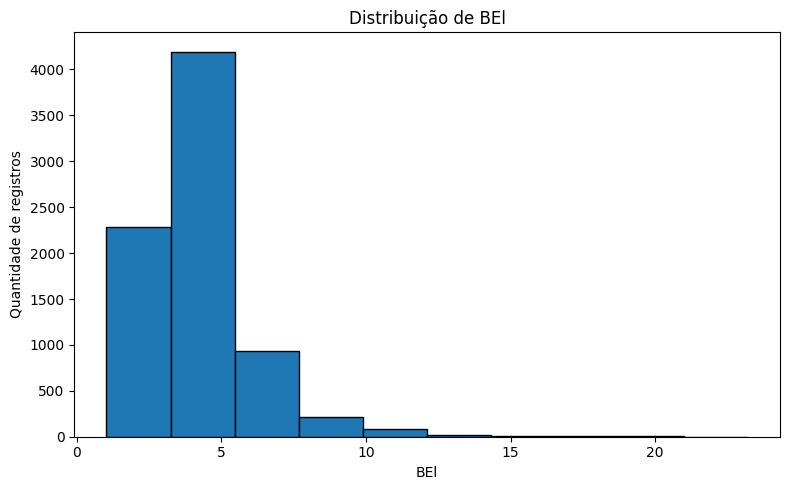

In [176]:

# Procura as colunas numéricas do dataset
colunas_numericas = dados[tracos].select_dtypes(
    include="number"
).columns.tolist()

# Verifica se existe alguma coluna numérica
if len(colunas_numericas) > 0:

    # Seleciona a primeira coluna numérica disponível
    coluna_tamanho = colunas_numericas[0]

    # Cria o histograma
    plt.figure(figsize=(8, 5))

    plt.hist(
        dados[coluna_tamanho].dropna(),
        bins=10,
        edgecolor="black"
    )

    # Adiciona o título e os nomes dos eixos
    plt.title("Distribuição de " + coluna_tamanho)
    plt.xlabel(coluna_tamanho)
    plt.ylabel("Quantidade de registros")

    # Ajusta o espaço do gráfico
    plt.tight_layout()

    # Exibe o gráfico
    plt.show()

else:
    print("Não foram encontradas colunas numéricas.")


# Passo 5 — Separar os dados em treino e teste
Explicação: Vou usar 80% dos registros para treinar os modelos e 20% para testar suas previsões. O stratify=y ajuda a manter a proporção das ordens nas duas partes.

In [177]:

# Separa os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Mostra a quantidade de dados em cada parte
print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)


Dados de treino: (6204, 9)
Dados de teste: (1551, 9)


# Passo 6 — Treinar os modelos e otimizar o SVM
Explicação: Vou treinar seis modelos de classificação. Como podem existir características sem valores, usaremos a imputação pela mediana para preencher os valores ausentes. O Pipeline organiza essa preparação junto com o modelo, e o GridSearchCV testa diferentes parâmetros para encontrar a melhor configuração do SVM.

In [178]:

# Cria o SVM linear com preparação dos dados
svm_linear = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="linear")
)

# Cria o SVM com Pipeline
svm_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC()
)

# Define os parâmetros que serão testados
parametros = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Cria o modelo que fará a otimização
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parametros,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Cria os seis modelos
modelos = {
    "SVM Linear": svm_linear,

    "SVM Pipeline": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_search,

    "Árvore de Decisão": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

# Guarda as previsões dos modelos
previsoes = {}

# Treina os modelos e faz as previsões
for nome, modelo in modelos.items():

    print("Treinando:", nome)

    # Treina com os dados de treino
    modelo.fit(X_treino, y_treino)

    # Prevê as classes dos dados de teste
    previsoes[nome] = modelo.predict(X_teste)

# Mostra os melhores parâmetros encontrados
print("\nMelhores parâmetros do SVM otimizado:")
print(grid_search.best_params_)

# Mostra a acurácia média da validação cruzada
print("\nMelhor acurácia na validação cruzada:")
print(grid_search.best_score_)


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM otimizado:
{'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Melhor acurácia na validação cruzada:
0.8167320839073587


# Passo 7 — Avaliar os resultados
Explicação: Vou calcular a acurácia de cada modelo, apresentar o relatório de classificação e comparar os resultados. O relatório inclui precision, recall e F1-score, que ajudam a avaliar o desempenho em cada ordem de peixe.


Modelo: SVM Linear
Acurácia: 72.15 %
                    precision    recall  f1-score   support

     Characiformes       0.66      0.68      0.67       256
      Clupeiformes       0.00      0.00      0.00        21
     Cypriniformes       0.60      0.61      0.60       387
Cyprinodontiformes       0.78      0.79      0.79       111
     Gymnotiformes       0.85      0.85      0.85        20
 Osteoglossiformes       0.76      0.52      0.62        31
       Perciformes       0.90      0.92      0.91       365
      Siluriformes       0.70      0.70      0.70       360

          accuracy                           0.72      1551
         macro avg       0.66      0.63      0.64      1551
      weighted avg       0.71      0.72      0.72      1551


Modelo: SVM Pipeline
Acurácia: 80.08 %
                    precision    recall  f1-score   support

     Characiformes       0.81      0.71      0.76       256
      Clupeiformes       0.33      0.10      0.15        21
     Cypriniformes

,Modelo,Acurácia
2,SVM Otimizado,0.811090
1,SVM Pipeline,0.800774
4,Random Forest,0.785300
5,Gradient Boosting,0.772405
0,SVM Linear,0.721470
3,Árvore de Decisão,0.686009


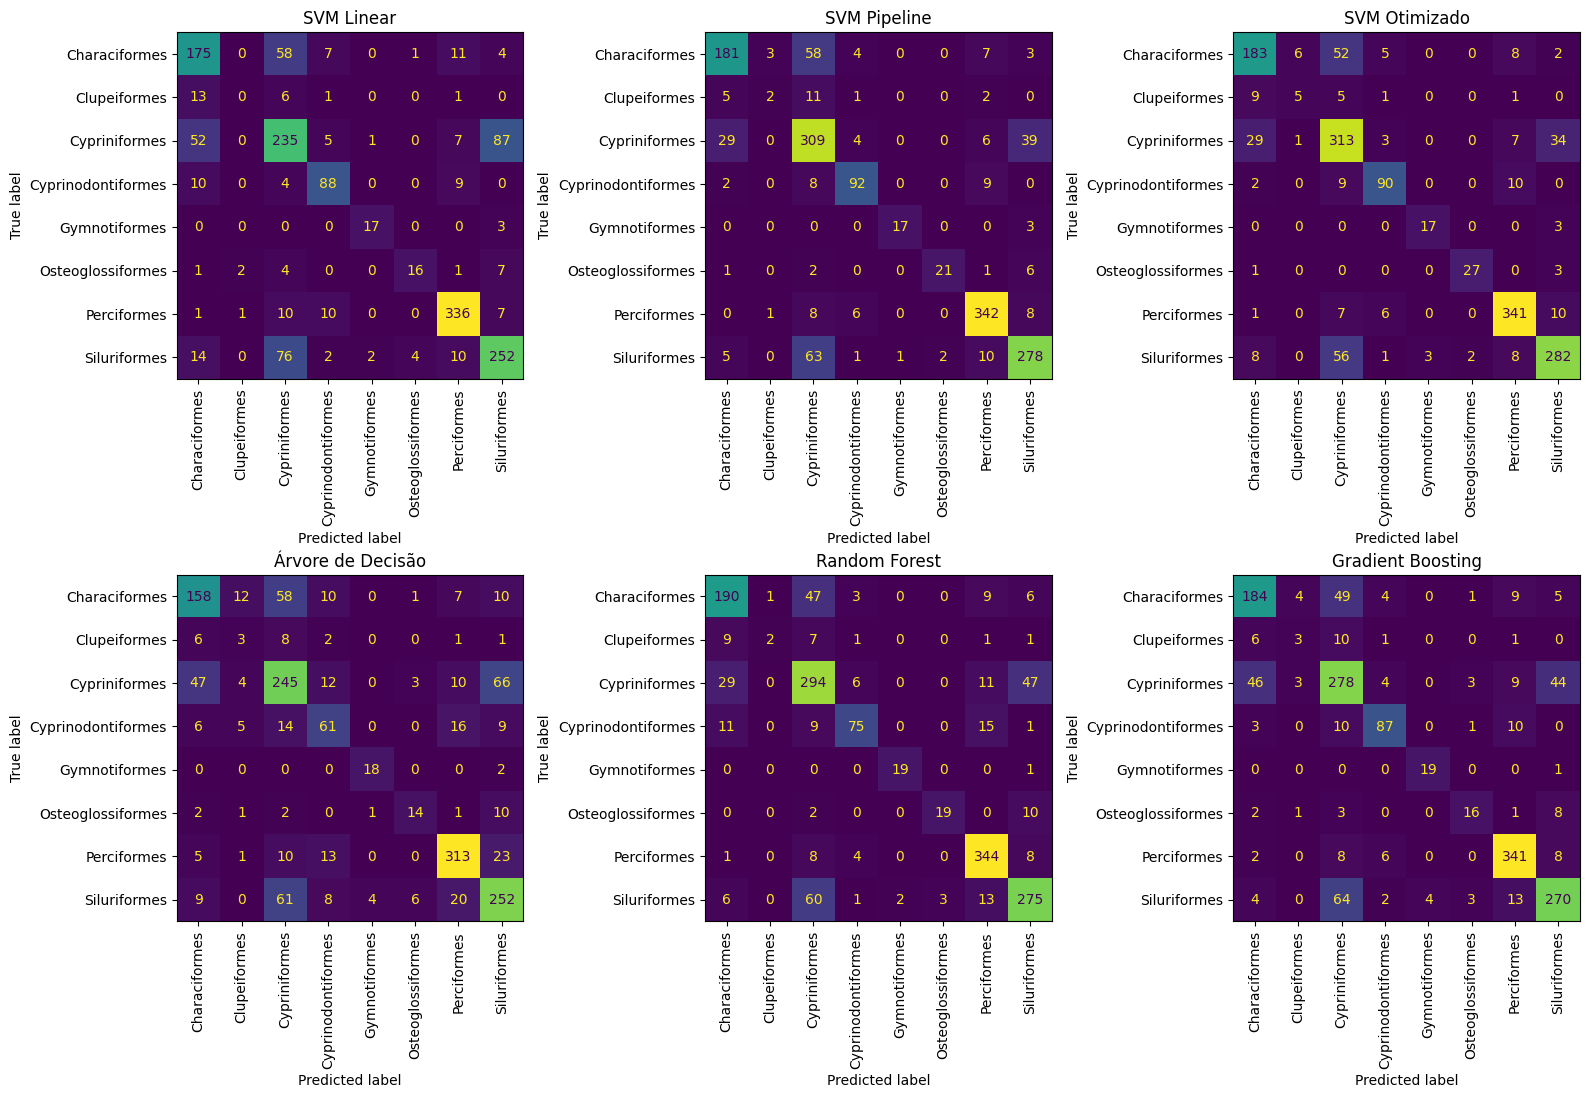

In [179]:

# Cria uma lista para guardar os resultados
resultados = []

# Avalia cada modelo
for nome, previsao in previsoes.items():

    # Calcula a acurácia no conjunto de teste
    acuracia = accuracy_score(y_teste, previsao)

    # Guarda o nome do modelo e sua acurácia
    resultados.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    # Mostra os resultados do modelo
    print("\nModelo:", nome)
    print("Acurácia:", round(acuracia * 100, 2), "%")

    # Mostra as métricas de classificação
    print(
        classification_report(
            y_teste,
            previsao,
            zero_division=0
        )
    )

# Organiza os modelos da maior para a menor acurácia
comparacao = pd.DataFrame(resultados)

comparacao = comparacao.sort_values(
    by="Acurácia",
    ascending=False
)

# Mostra a tabela comparativa
print("\nComparação das acurácias:")
display(comparacao)

# Cria as matrizes de confusão dos seis modelos
fig, eixos = plt.subplots(2, 3, figsize=(16, 11))

# Desenha uma matriz para cada modelo
for eixo, (nome, previsao) in zip(
    eixos.flatten(),
    previsoes.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        previsao,
        ax=eixo,
        colorbar=False,
        xticks_rotation=90
    )

    # Adiciona o nome do modelo
    eixo.set_title(nome)

# Ajusta o espaço entre os gráficos
plt.tight_layout()

# Exibe as matrizes de confusão
plt.show()


Gráfico de barras — Comparação dos modelos
Explicação: Este gráfico compara a porcentagem de previsões corretas dos seis modelos, facilitando a identificação daquele que apresentou a maior acurácia no conjunto de teste.

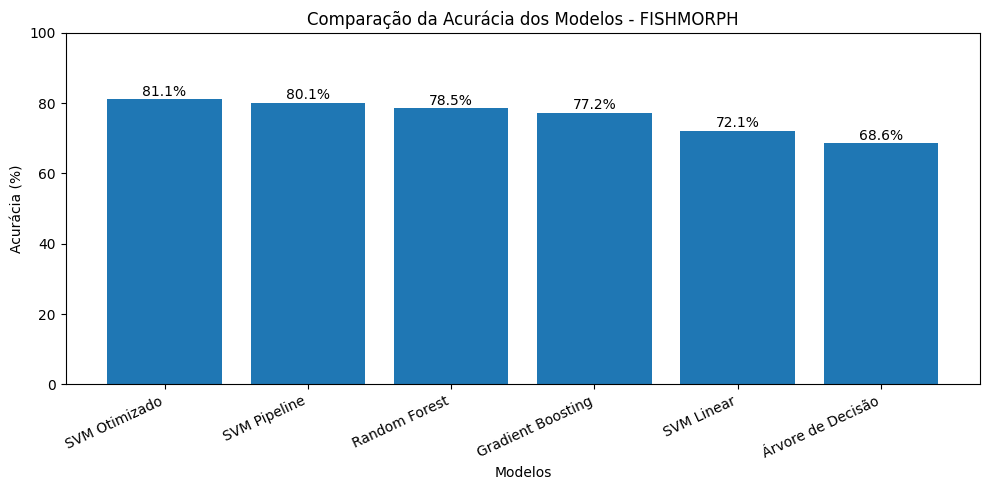

In [180]:

# Cria o gráfico de comparação
plt.figure(figsize=(10, 5))

# Desenha as barras com a acurácia em porcentagem
plt.bar(
    comparacao["Modelo"],
    comparacao["Acurácia"] * 100
)

# Adiciona o título e os nomes dos eixos
plt.title("Comparação da Acurácia dos Modelos - FISHMORPH")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

# Inclina os nomes para facilitar a leitura
plt.xticks(rotation=25, ha="right")

# Define o limite do eixo vertical
plt.ylim(0, 100)

# Mostra a porcentagem acima de cada barra
for i, valor in enumerate(comparacao["Acurácia"] * 100):
    plt.text(i, valor + 1, f"{valor:.1f}%", ha="center")

# Ajusta o espaço do gráfico
plt.tight_layout()

# Exibe o gráfico
plt.show()


# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.713,0.721,0.717
1,SVM Pipeline,0.803,0.801,0.798
2,SVM Otimizado,0.812,0.811,0.810
3,Árvore de Decisão,0.687,0.686,0.686
4,Random Forest,0.786,0.785,0.781
5,Gradient Boosting,0.770,0.772,0.770


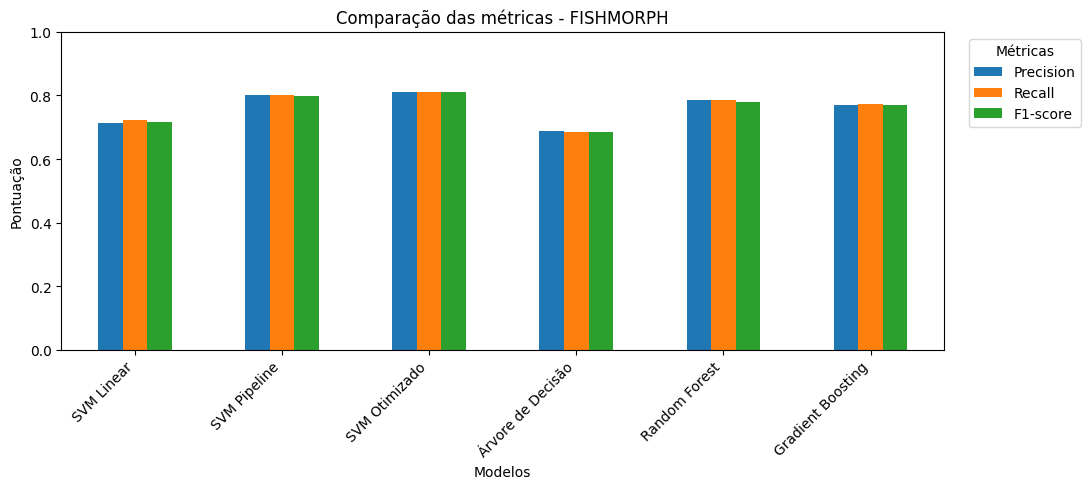

<Figure size 640x480 with 0 Axes>

In [181]:

# Calcula as métricas de classificação dos peixes
metricas_fish = []

for nome, previsao in previsoes.items():
    metricas_fish.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste, previsao, average="weighted", zero_division=0)
    })

# Organiza os resultados
df_metricas_fish = pd.DataFrame(metricas_fish)
display(df_metricas_fish.round(3))

# Mostra o desempenho dos seis modelos
df_metricas_fish.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - FISHMORPH")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Após treinar e avaliar os seis modelos, vou identificar aquele que apresentou a maior acurácia no conjunto de teste e apresentar o resultado obtido na classificação das ordens taxonômicas dos peixes.

In [182]:
# Identifica o modelo com a maior acurácia no teste
melhor_modelo = comparacao.loc[comparacao["Acurácia"].idxmax()]

# Mostra a conclusão dos resultados
print("CONCLUSÃO")
print()
print("O modelo com a maior acurácia no teste foi:",
      melhor_modelo["Modelo"])
print("Acurácia obtida:",
      round(melhor_modelo["Acurácia"] * 100, 2), "%")

print()
print("Os modelos foram utilizados para classificar os peixes")
print("com base nas características disponíveis no dataset.")
print("A comparação das acurácias permitiu identificar")
print("qual modelo apresentou o melhor resultado no teste.")
print("Assim, foi possível praticar o treinamento e a avaliação")
print("de diferentes modelos de aprendizado de máquina.")

CONCLUSÃO

O modelo com a maior acurácia no teste foi: SVM Otimizado
Acurácia obtida: 81.11 %

Os modelos foram utilizados para classificar os peixes
com base nas características disponíveis no dataset.
A comparação das acurácias permitiu identificar
qual modelo apresentou o melhor resultado no teste.
Assim, foi possível praticar o treinamento e a avaliação
de diferentes modelos de aprendizado de máquina.


# Dataset 3 — Student Stress Factors
O dataset Student Stress Factors reúne informações relacionadas ao estresse dos estudantes, considerando fatores psicológicos, acadêmicos, sociais e ambientais.

Nosso objetivo será treinar seis modelos de classificação para prever o nível de estresse dos estudantes com base nessas características.

# Passo 1 — Importação das bibliotecas
Explicação: Vou importar as bibliotecas necessárias para organizar os dados, criar gráficos, separar os registros em treino e teste, treinar os modelos e avaliar seus resultados.

In [183]:

# Biblioteca para organizar os dados
import pandas as pd

# Bibliotecas para criar gráficos
import matplotlib.pyplot as plt

# Ferramentas para separar os dados e otimizar parâmetros
from sklearn.model_selection import train_test_split, GridSearchCV

# Ferramentas para preparar os dados
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliar os modelos
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# Passo 2 — Baixar e carregar o dataset
Explicação: Vou baixar o dataset diretamente do Kaggle utilizando a biblioteca kagglehub. Depois, vou localizar o arquivo que contém os dados dos estudantes e carregá-lo em uma tabela.

In [184]:

# Instala a biblioteca para baixar datasets do Kaggle
!pip install -q kagglehub

# Importa as bibliotecas necessárias
import kagglehub
import os

# Baixa o dataset
path = kagglehub.dataset_download(
    "rxnach/student-stress-factors-a-comprehensive-analysis"
)

# Procura os arquivos CSV disponíveis
arquivos = []

for pasta, subpastas, nomes in os.walk(path):
    for nome in nomes:
        if nome.lower().endswith(".csv"):
            arquivos.append(os.path.join(pasta, nome))

# Mostra os arquivos encontrados
print("Arquivos CSV encontrados:")
for arquivo in arquivos:
    print(arquivo)

# Carrega o arquivo quando houver apenas um CSV
if len(arquivos) == 1:
    df = pd.read_csv(arquivos[0])
    print("\nDataset carregado com sucesso!")
    display(df.head())
elif len(arquivos) == 0:
    print("Nenhum arquivo CSV foi encontrado.")
else:
    print("\nExistem vários arquivos. Precisamos escolher o correto.")


Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
Arquivos CSV encontrados:
/kaggle/input/student-stress-factors-a-comprehensive-analysis/StressLevelDataset.csv

Dataset carregado com sucesso!


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


# Passo 3 — Conhecendo os dados
Explicação: Antes de treinar os modelos, vou verificar a quantidade de linhas e colunas, os tipos de dados e a existência de valores ausentes. Isso ajuda a entender como o dataset está organizado e quais informações poderão ser utilizadas.

In [185]:

# Mostra a quantidade de linhas e colunas
print("Tamanho do dataset:", df.shape)

# Mostra os nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

# Mostra os tipos de dados e informações gerais
print("\nInformações:")
df.info()

# Verifica os valores ausentes
print("\nValores ausentes:")
print(df.isnull().sum())

# Mostra os primeiros registros
print("\nPrimeiras linhas:")
display(df.head())


Tamanho do dataset: (1100, 21)

Colunas:
['anxiety_level', 'self_esteem', 'mental_health_history', 'depression', 'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem', 'noise_level', 'living_conditions', 'safety', 'basic_needs', 'academic_performance', 'study_load', 'teacher_student_relationship', 'future_career_concerns', 'social_support', 'peer_pressure', 'extracurricular_activities', 'bullying', 'stress_level']

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null 

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


# Passo 4 — Preparar os dados para a classificação
Explicação: Vou utilizar o nível de estresse (stress_level) como variável que queremos prever. As demais características dos estudantes serão usadas para treinar os modelos. Também vou verificar os valores ausentes e preparar as colunas para que os algoritmos consigam trabalhar com elas.

In [186]:

# Organiza os nomes das colunas
df.columns = df.columns.str.strip()

# Define a coluna que queremos prever
coluna_alvo = "stress_level"

# Verifica se a coluna existe
if coluna_alvo not in df.columns:
    raise ValueError("A coluna stress_level não foi encontrada.")

# Remove registros sem a classificação
dados = df.dropna(subset=[coluna_alvo]).copy()

# Separa as características e a classificação
X = dados.drop(columns=[coluna_alvo])
y = dados[coluna_alvo]

# Converte colunas de texto em valores numéricos
X = pd.get_dummies(X, dtype=int)

# Mostra as classes existentes
print("Níveis de estresse:")
print(y.value_counts().sort_index())

# Mostra a quantidade de características
print("\nQuantidade de características:", X.shape[1])

# Mostra os primeiros registros preparados
display(X.head())


Níveis de estresse:
stress_level
0    373
1    358
2    369
Name: count, dtype: int64

Quantidade de características: 20


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
0,14,20,0,11,2,1,2,4,2,3,3,2,3,2,3,3,2,3,3,2
1,15,8,1,15,5,3,1,4,3,1,2,2,1,4,1,5,1,4,5,5
2,12,18,1,14,2,1,2,2,2,2,3,2,2,3,3,2,2,3,2,2
3,16,12,1,15,4,3,1,3,4,2,2,2,2,4,1,4,1,4,4,5
4,16,28,0,7,2,3,5,1,3,2,4,3,4,3,1,2,1,5,0,5


# Passo 4.1 — Análise exploratória dos dados
Explicação: Vou criar um gráfico para visualizar a quantidade de estudantes em cada nível de estresse. Isso permite observar a distribuição das classes antes do treinamento.

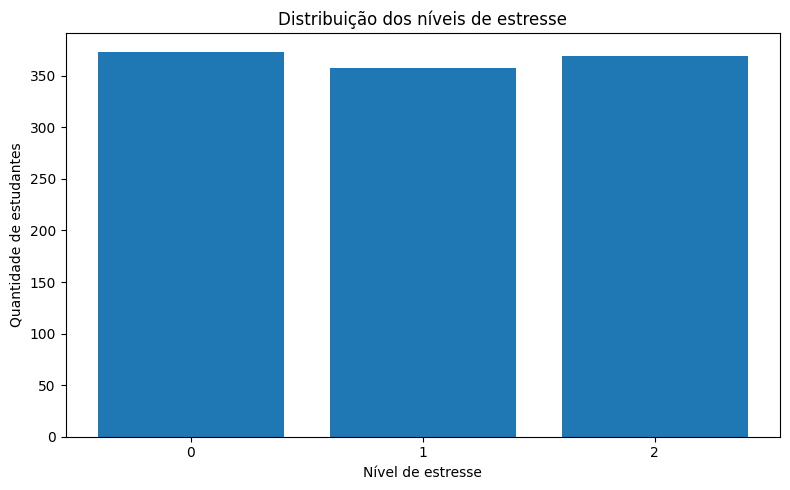

In [187]:

# Conta os estudantes por nível de estresse
contagem = y.value_counts().sort_index()

# Cria o gráfico de barras
plt.figure(figsize=(8, 5))

plt.bar(
    contagem.index.astype(str),
    contagem.values
)

# Adiciona o título e os nomes dos eixos
plt.title("Distribuição dos níveis de estresse")
plt.xlabel("Nível de estresse")
plt.ylabel("Quantidade de estudantes")

# Exibe o gráfico
plt.tight_layout()
plt.show()


# Passo 5 — Divisão entre treino e teste
Explicação: Vou separar 80% dos registros para treinar os modelos e 20% para testar suas previsões. O stratify=y ajuda a manter a proporção dos níveis de estresse nos dois conjuntos.

In [188]:

# Separa os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Mostra a quantidade de registros
print("Dados de treino:", X_treino.shape)
print("Dados de teste:", X_teste.shape)


Dados de treino: (880, 20)
Dados de teste: (220, 20)


# Passo 6 — Treinar os modelos e otimizar o SVM
Explicação: Vou treinar os mesmos seis modelos utilizados nos datasets anteriores. Para o SVM, vou utilizar a padronização dos dados e testar diferentes parâmetros com o GridSearchCV. Também vou tratar possíveis valores ausentes durante o treinamento.

In [189]:

# Cria o SVM linear com preparação dos dados
svm_linear = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="linear")
)

# Cria o SVM com Pipeline
svm_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC()
)

# Define os parâmetros que serão testados
parametros = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Configura a otimização do SVM
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parametros,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Cria os seis modelos
modelos = {
    "SVM Linear": svm_linear,

    "SVM Pipeline": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_search,

    "Árvore de Decisão": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

# Guarda as previsões dos modelos
previsoes = {}

# Treina os modelos e faz as previsões
for nome, modelo in modelos.items():

    print("Treinando:", nome)

    # Treina o modelo
    modelo.fit(X_treino, y_treino)

    # Faz as previsões
    previsoes[nome] = modelo.predict(X_teste)

# Mostra os melhores parâmetros encontrados
print("\nMelhores parâmetros do SVM otimizado:")
print(grid_search.best_params_)

# Mostra a acurácia da validação cruzada
print("\nMelhor acurácia na validação cruzada:")
print(grid_search.best_score_)


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM otimizado:
{'svc__C': 10, 'svc__kernel': 'linear'}

Melhor acurácia na validação cruzada:
0.8852272727272726


# Passo 7 — Avaliar os resultados
Explicação: Vou calcular a acurácia dos seis modelos e apresentar o relatório de classificação. Também vou criar as matrizes de confusão para visualizar os acertos e erros nas previsões.


Modelo: SVM Linear
Acurácia: 88.64 %
              precision    recall  f1-score   support

           0       0.90      0.82      0.86        74
           1       0.89      0.93      0.91        72
           2       0.87      0.91      0.89        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220


Modelo: SVM Pipeline
Acurácia: 87.73 %
              precision    recall  f1-score   support

           0       0.87      0.84      0.86        74
           1       0.90      0.92      0.91        72
           2       0.86      0.88      0.87        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220


Modelo: SVM Otimizado
Acurácia: 89.09 %
              precision    recall  f1-score   support

           0       0.91      0.82      0.87        74
          

,Modelo,Acurácia
4,Random Forest,0.890909
2,SVM Otimizado,0.890909
0,SVM Linear,0.886364
1,SVM Pipeline,0.877273
5,Gradient Boosting,0.872727
3,Árvore de Decisão,0.854545


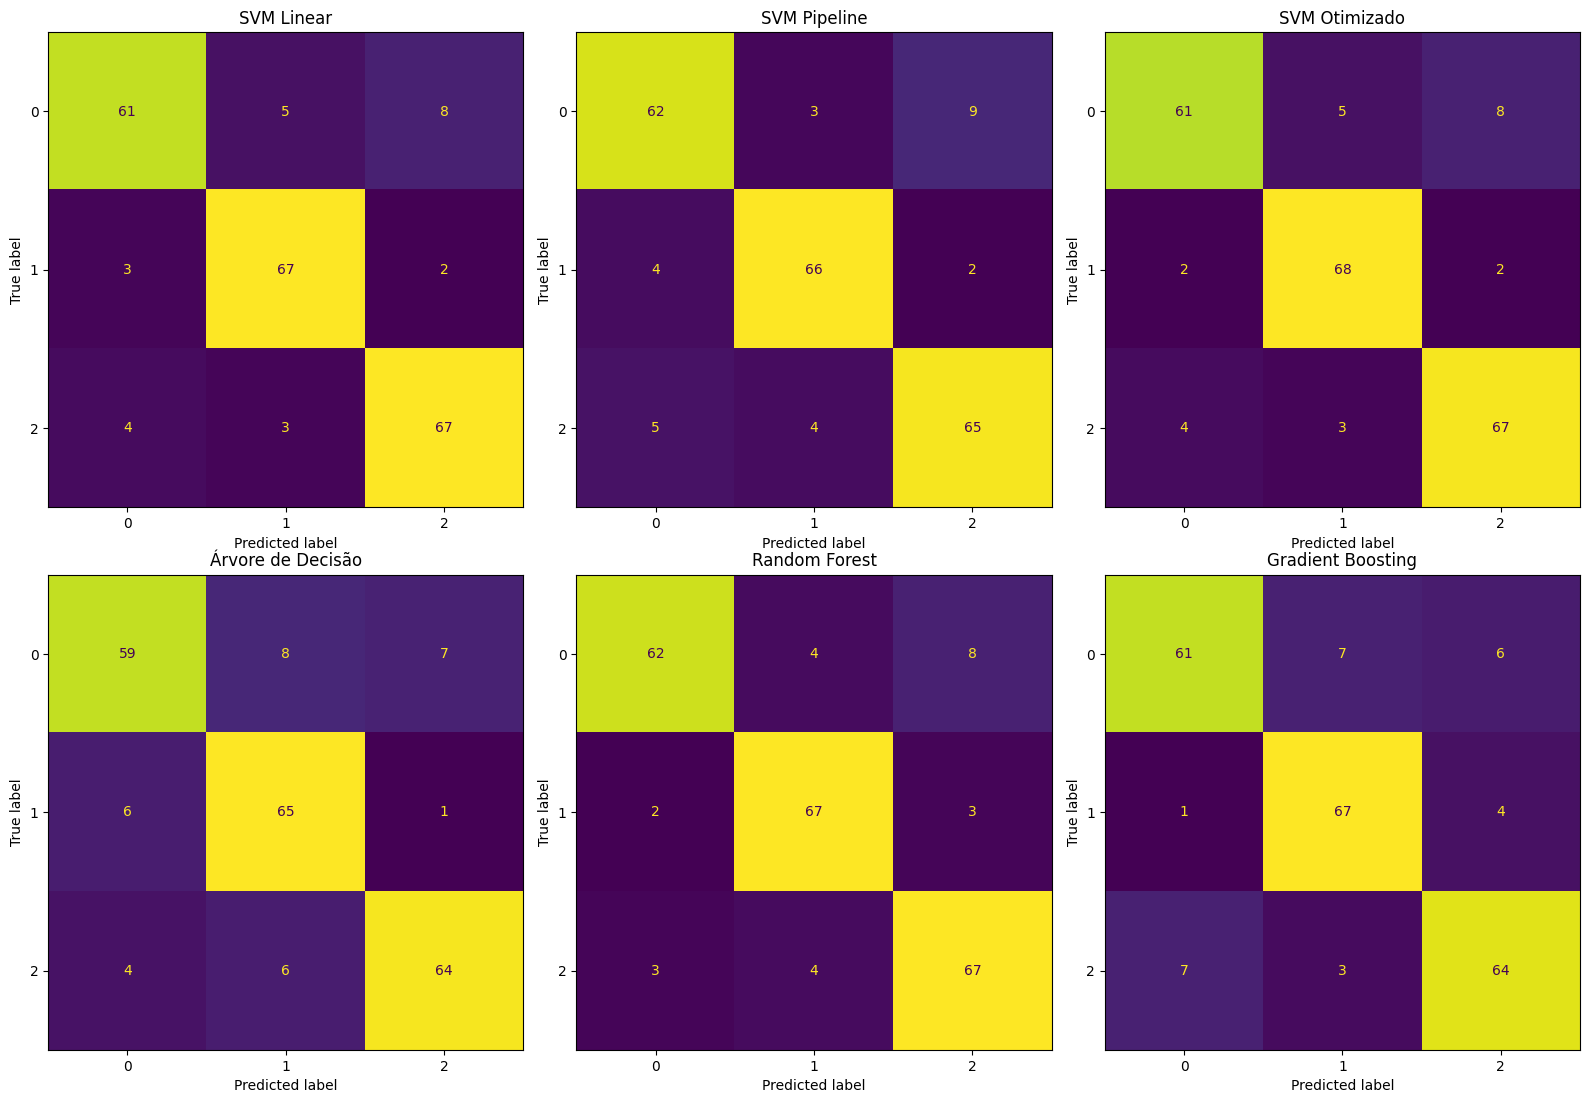

In [190]:

# Cria uma lista para guardar os resultados
resultados = []

# Avalia cada modelo
for nome, previsao in previsoes.items():

    # Calcula a acurácia
    acuracia = accuracy_score(y_teste, previsao)

    # Guarda o resultado
    resultados.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    # Mostra o relatório de classificação
    print("\nModelo:", nome)
    print("Acurácia:", round(acuracia * 100, 2), "%")

    print(
        classification_report(
            y_teste,
            previsao,
            zero_division=0
        )
    )

# Organiza os resultados
comparacao = pd.DataFrame(resultados)

comparacao = comparacao.sort_values(
    by="Acurácia",
    ascending=False
)

# Mostra a comparação
print("\nComparação das acurácias:")
display(comparacao)

# Cria as matrizes de confusão
fig, eixos = plt.subplots(2, 3, figsize=(16, 11))

# Desenha uma matriz para cada modelo
for eixo, (nome, previsao) in zip(
    eixos.flatten(),
    previsoes.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_teste,
        previsao,
        ax=eixo,
        colorbar=False
    )

    eixo.set_title(nome)

# Ajusta os gráficos
plt.tight_layout()
plt.show()


# Gráfico de barras — Comparação dos modelos
Explicação: Este gráfico compara a acurácia dos seis modelos, mostrando a porcentagem de previsões corretas de cada um. Assim, será possível identificar visualmente as diferenças de desempenho.

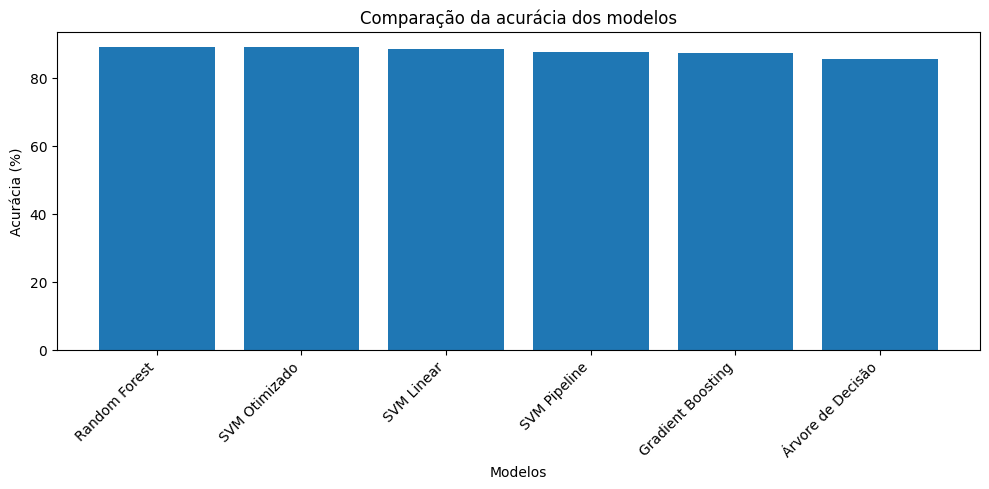

In [191]:

# Cria o gráfico de comparação
plt.figure(figsize=(10, 5))

# Mostra a acurácia em porcentagem
plt.bar(
    comparacao["Modelo"],
    comparacao["Acurácia"] * 100
)

# Adiciona o título e os nomes dos eixos
plt.title("Comparação da acurácia dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

# Ajusta os nomes dos modelos
plt.xticks(rotation=45, ha="right")

# Exibe o gráfico
plt.tight_layout()
plt.show()


# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.887,0.886,0.886
1,SVM Pipeline,0.877,0.877,0.877
2,SVM Otimizado,0.892,0.891,0.890
3,Árvore de Decisão,0.856,0.855,0.854
4,Random Forest,0.893,0.891,0.891
5,Gradient Boosting,0.873,0.873,0.872


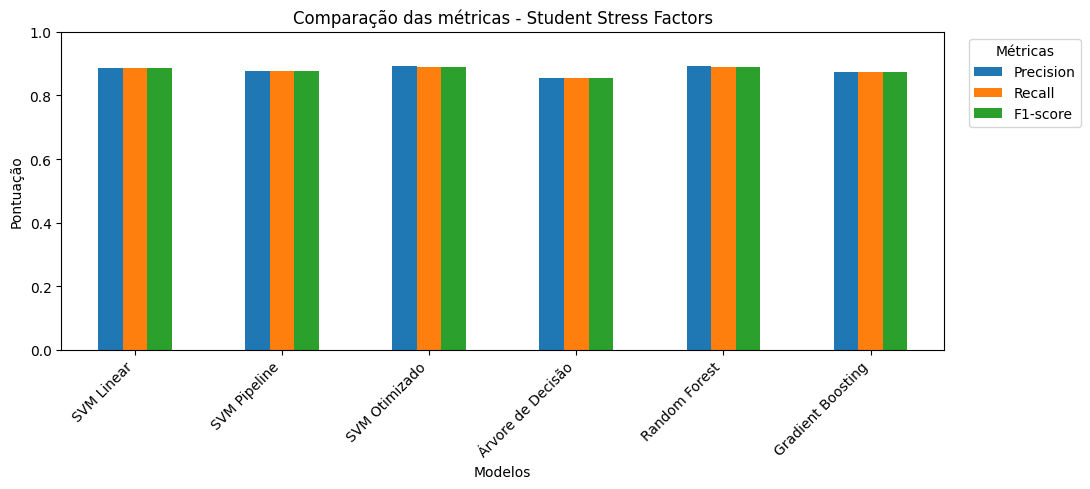

<Figure size 640x480 with 0 Axes>

In [192]:

# Calcula as métricas dos modelos de estresse
metricas_stress = []

for nome, previsao in previsoes.items():
    metricas_stress.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste, previsao, average="weighted", zero_division=0)
    })

# Cria a tabela comparativa
df_metricas_stress = pd.DataFrame(metricas_stress)
display(df_metricas_stress.round(3))

# Gera o gráfico das três métricas
df_metricas_stress.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - Student Stress Factors")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Depois de executar os modelos, vou identificar aquele que apresentou a maior acurácia no conjunto de teste e registrar o resultado obtido.

In [193]:

# Identifica todos os modelos empatados na maior acurácia
maior_acuracia = comparacao["Acurácia"].max()

melhores_modelos = comparacao[
    comparacao["Acurácia"].round(6) == round(maior_acuracia, 6)
]

print("CONCLUSÃO")
print()
print("Modelos com maior acurácia:")
print(", ".join(melhores_modelos["Modelo"]))
print("Acurácia obtida:", round(maior_acuracia * 100, 2), "%")

print()
print("Os seis modelos foram comparados para classificar")
print("os níveis de estresse dos estudantes.")


CONCLUSÃO

Modelos com maior acurácia:
Random Forest, SVM Otimizado
Acurácia obtida: 89.09 %

Os seis modelos foram comparados para classificar
os níveis de estresse dos estudantes.


# Dataset 4 — Breast Cancer Wisconsin (Diagnostic)
Tema: Diagnóstico de câncer de mama

Fonte: Breast Cancer Wisconsin — Kaggle

O dataset Breast Cancer Wisconsin contém características extraídas de imagens de células de tumores mamários. Essas informações são utilizadas para identificar se um tumor é benigno ou maligno.

O objetivo desta análise é utilizar algoritmos de Machine Learning para classificar os tumores com base em suas características, comparando o desempenho dos seis modelos.

# Passo 1 — Importação das bibliotecas
Explicação: Vou importar as bibliotecas necessárias para organizar os dados, criar gráficos, preparar as informações, treinar os modelos e avaliar os resultados.

In [194]:

# Bibliotecas para organizar e visualizar os dados
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ferramentas para preparação e divisão dos dados
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliar os resultados
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# Passo 2 — Carregamento do dataset
Explicação: Vou baixar o dataset diretamente do Kaggle utilizando a biblioteca kagglehub e carregar os dados em um DataFrame para começar a análise.

In [195]:

# Instala a biblioteca KaggleHub
!pip install -q kagglehub

import kagglehub
import os

# Baixa o dataset
path = kagglehub.dataset_download(
    "uciml/breast-cancer-wisconsin-data"
)

# Localiza os arquivos CSV
arquivos = []

for pasta, subpastas, nomes in os.walk(path):
    for nome in nomes:
        if nome.lower().endswith(".csv"):
            arquivos.append(os.path.join(pasta, nome))

print("Arquivos encontrados:")
print(arquivos)

# Carrega o dataset quando houver apenas um CSV
if len(arquivos) == 1:
    df_cancer = pd.read_csv(arquivos[0])
    print("\nDataset carregado com sucesso!")
    display(df_cancer.head())
else:
    raise ValueError(
        "Verifique os arquivos CSV encontrados antes de continuar."
    )


Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Arquivos encontrados:
['/kaggle/input/breast-cancer-wisconsin-data/data.csv']

Dataset carregado com sucesso!


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


#Passo 3 — Conhecendo os dados
Explicação: Vou verificar a quantidade de registros, os nomes das colunas, os tipos de dados e a existência de valores ausentes. Isso permite compreender melhor as informações antes do treinamento.

In [196]:

# Mostra a quantidade de linhas e colunas
print("Tamanho do dataset:", df_cancer.shape)

# Mostra os nomes das colunas
print("\nColunas:")
print(df_cancer.columns.tolist())

# Mostra informações gerais
print("\nInformações:")
df_cancer.info()

# Verifica valores ausentes
print("\nValores ausentes:")
print(df_cancer.isnull().sum())

# Mostra as primeiras linhas
display(df_cancer.head())


Tamanho do dataset: (569, 33)

Colunas:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null   

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


# Passo 4 — Preparação dos dados para classificação
Explicação: Vou utilizar a coluna diagnosis como variável que queremos prever. O valor M representa tumores malignos e B representa tumores benignos. Também vou remover colunas que não contribuem para a classificação, como identificadores e colunas vazias.

In [197]:

# Cria uma cópia dos dados
dados_cancer = df_cancer.copy()

# Remove espaços dos nomes das colunas
dados_cancer.columns = dados_cancer.columns.str.strip()

# Remove colunas que não serão utilizadas
dados_cancer = dados_cancer.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Remove registros sem diagnóstico
dados_cancer = dados_cancer.dropna(subset=["diagnosis"])

# Converte o diagnóstico em valores numéricos
dados_cancer["diagnosis"] = dados_cancer["diagnosis"].map({
    "B": 0,
    "M": 1
})

# Separa as características e o diagnóstico
X_cancer = dados_cancer.drop(columns=["diagnosis"])
y_cancer = dados_cancer["diagnosis"]

# Mostra a distribuição dos diagnósticos
print("Distribuição dos diagnósticos:")
print(y_cancer.value_counts())

# Mostra os dados preparados
display(dados_cancer.head())


Distribuição dos diagnósticos:
diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Passo 4.1 — Análise exploratória dos dados
Explicação: Vou criar um gráfico para visualizar a quantidade de tumores benignos e malignos presentes no dataset.

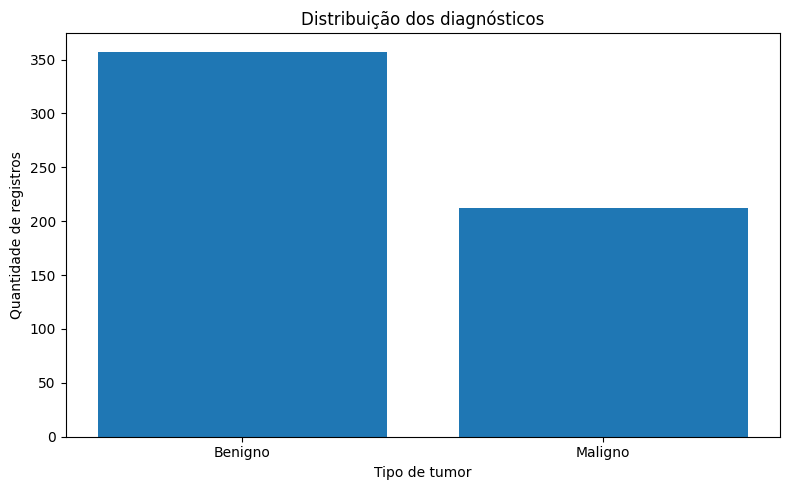

In [198]:

# Conta os diagnósticos
contagem = y_cancer.value_counts().sort_index()

# Cria o gráfico
plt.figure(figsize=(8, 5))

plt.bar(
    ["Benigno", "Maligno"],
    contagem.values
)

# Adiciona título e nomes dos eixos
plt.title("Distribuição dos diagnósticos")
plt.xlabel("Tipo de tumor")
plt.ylabel("Quantidade de registros")

# Exibe o gráfico
plt.tight_layout()
plt.show()


# Passo 4.2 — Matriz de correlação
Explicação: Vou analisar a correlação entre as características dos tumores e o diagnóstico. Essa visualização ajuda a identificar quais variáveis apresentam relações mais fortes entre si.

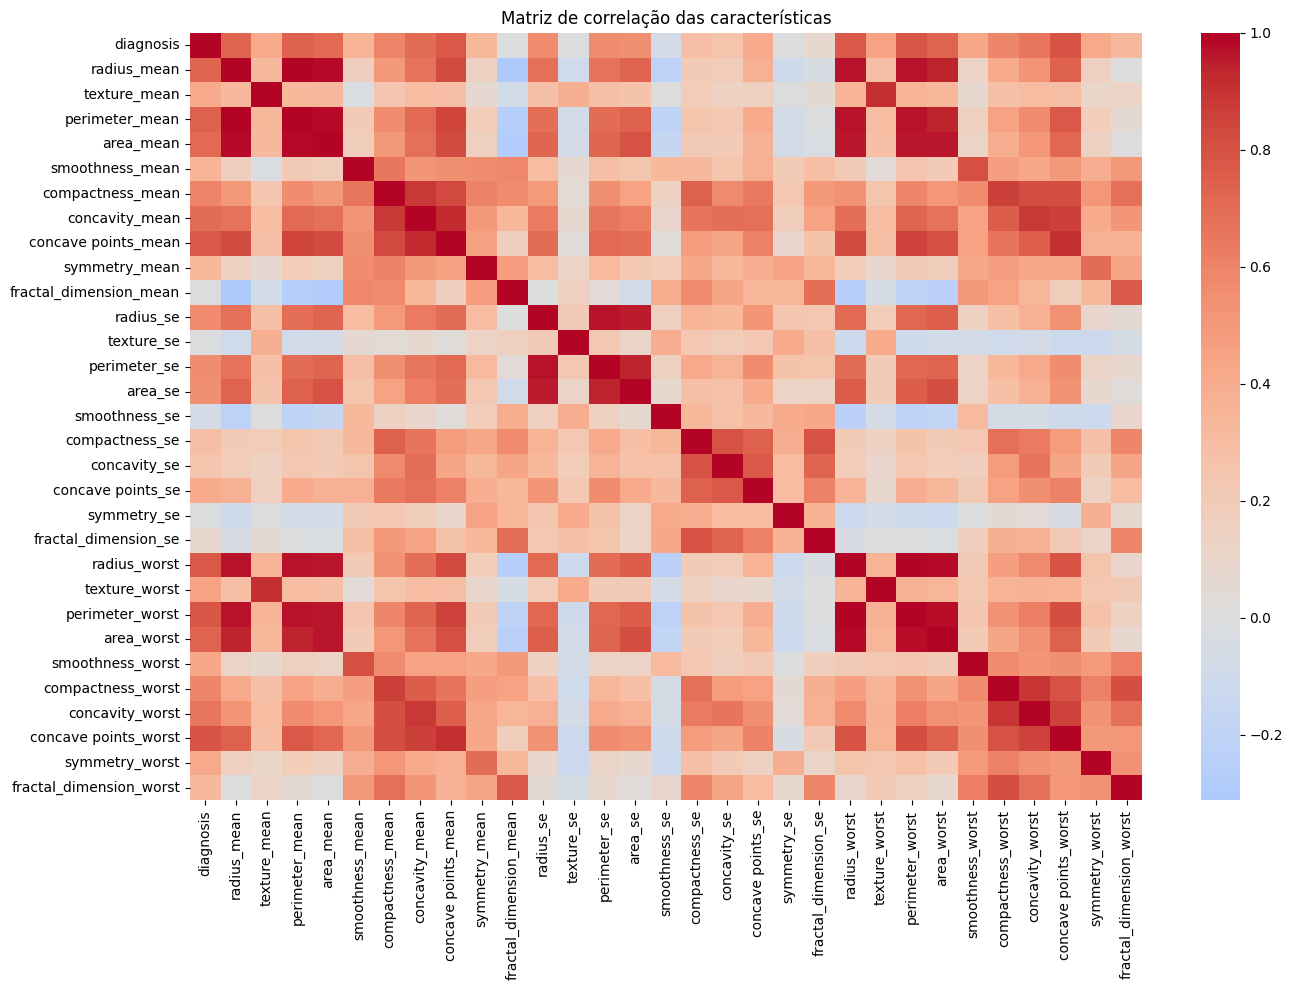

In [199]:

# Calcula a correlação das variáveis
correlacao = dados_cancer.corr(numeric_only=True)

# Cria o mapa de calor
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlacao,
    cmap="coolwarm",
    center=0
)

# Adiciona o título
plt.title("Matriz de correlação das características")

# Exibe o gráfico
plt.tight_layout()
plt.show()


# Passo 5 — Divisão entre treino e teste
Explicação: Vou separar 80% dos registros para treinar os modelos e 20% para testar as previsões. A divisão estratificada mantém a proporção de tumores benignos e malignos nos dois conjuntos.

In [200]:

# Divide os dados em treino e teste
X_treino_cancer, X_teste_cancer, y_treino_cancer, y_teste_cancer = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.2,
    random_state=42,
    stratify=y_cancer
)

# Mostra a quantidade de registros
print("Dados de treino:", X_treino_cancer.shape)
print("Dados de teste:", X_teste_cancer.shape)


Dados de treino: (455, 30)
Dados de teste: (114, 30)


# Passo 6 — Treinar os modelos e otimizar o SVM
Explicação: Vou treinar seis modelos de classificação: SVM Linear, SVM Pipeline, SVM Otimizado, Árvore de Decisão, Random Forest e Gradient Boosting. No SVM Otimizado, utilizarei o GridSearchCV para encontrar os melhores parâmetros.

In [201]:

# Cria o SVM linear com padronização
svm_linear = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="linear")
)

# Cria o SVM para otimização
svm_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC()
)

# Define os parâmetros para testar
parametros = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Configura a busca pelos melhores parâmetros
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parametros,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Organiza os seis modelos
modelos_cancer = {
    "SVM Linear": svm_linear,

    "SVM Pipeline": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_search,

    "Árvore de Decisão": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

# Guarda as previsões
previsoes_cancer = {}

# Treina e testa cada modelo
for nome, modelo in modelos_cancer.items():

    print("Treinando:", nome)

    modelo.fit(X_treino_cancer, y_treino_cancer)

    previsoes_cancer[nome] = modelo.predict(X_teste_cancer)

# Mostra os melhores parâmetros encontrados
print("\nMelhores parâmetros do SVM:")
print(grid_search.best_params_)

print("\nMelhor acurácia na validação cruzada:")
print(grid_search.best_score_)


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM:
{'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Melhor acurácia na validação cruzada:
0.9736263736263737


# Passo 7 — Avaliar os resultados
Explicação: Vou calcular a acurácia dos seis modelos e apresentar os relatórios de classificação. Também vou visualizar as matrizes de confusão, que mostram quantos tumores benignos e malignos foram classificados corretamente ou incorretamente.


Modelo: SVM Linear
Acurácia: 96.49 %
              precision    recall  f1-score   support

     Benigno       0.95      1.00      0.97        72
     Maligno       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114


Modelo: SVM Pipeline
Acurácia: 97.37 %
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Modelo: SVM Otimizado
Acurácia: 97.37 %
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro 

,Modelo,Acurácia
1,SVM Pipeline,0.973684
2,SVM Otimizado,0.973684
4,Random Forest,0.973684
0,SVM Linear,0.964912
5,Gradient Boosting,0.964912
3,Árvore de Decisão,0.929825


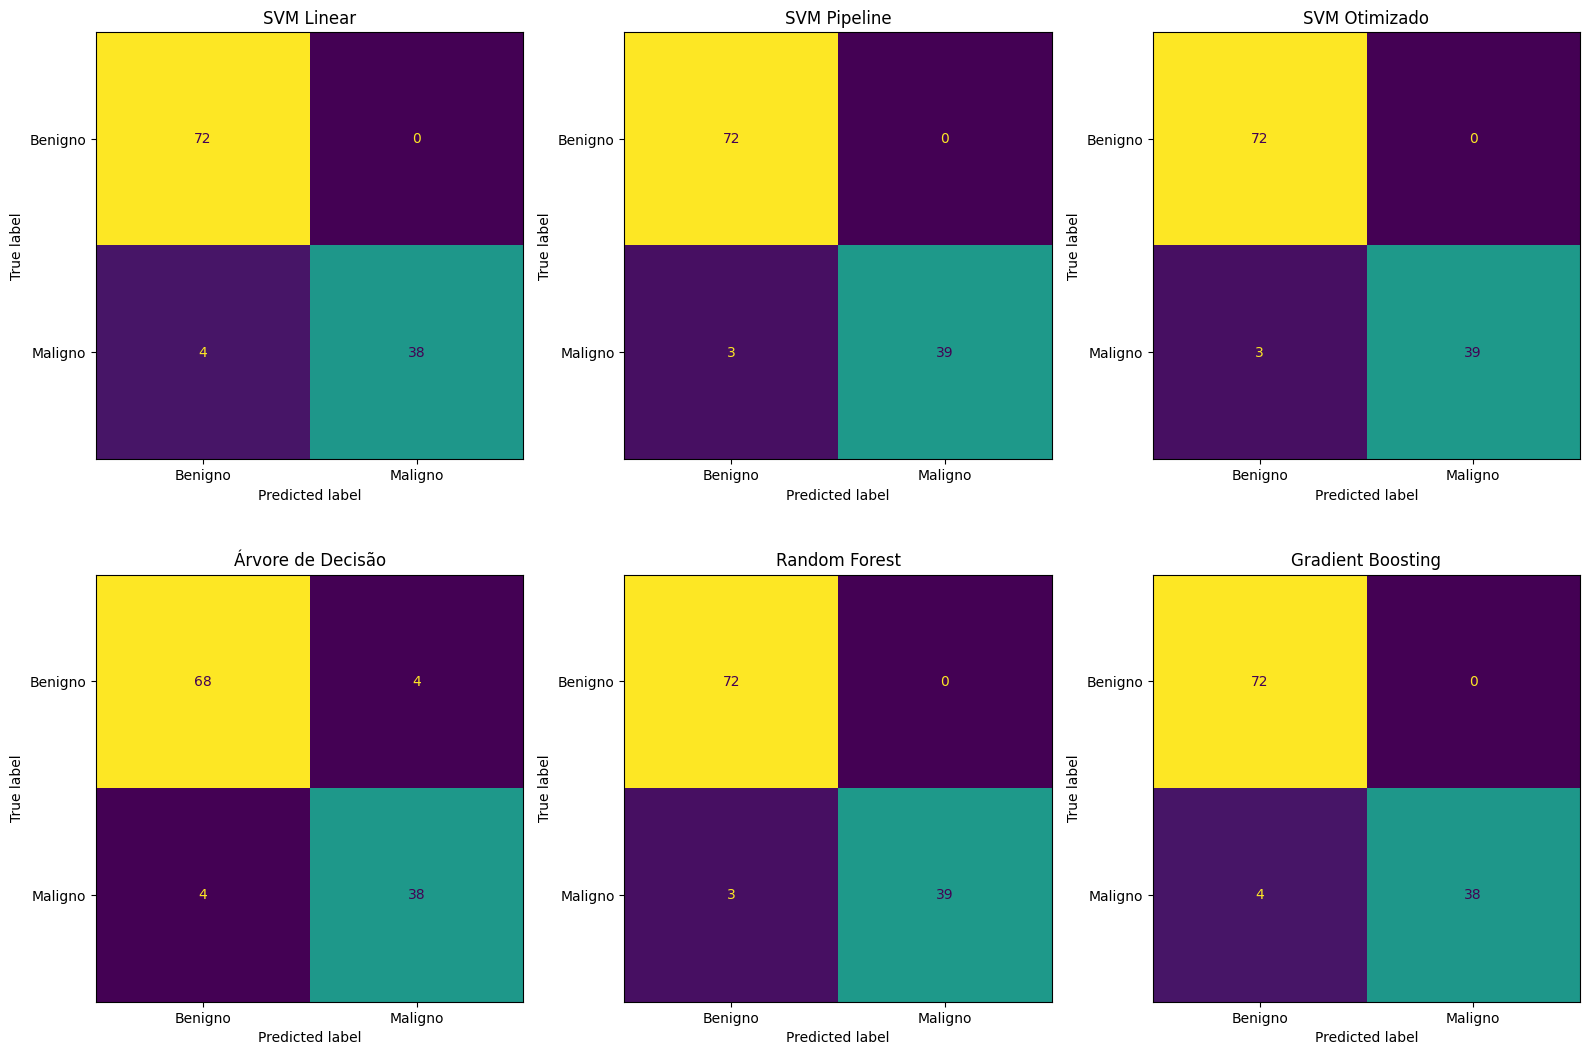

In [202]:

# Cria uma lista para guardar os resultados
resultados_cancer = []

# Avalia cada modelo
for nome, previsao in previsoes_cancer.items():

    acuracia = accuracy_score(y_teste_cancer, previsao)

    resultados_cancer.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    print("\nModelo:", nome)
    print("Acurácia:", round(acuracia * 100, 2), "%")

    print(
        classification_report(
            y_teste_cancer,
            previsao,
            target_names=["Benigno", "Maligno"],
            zero_division=0
        )
    )

# Organiza a comparação
comparacao_cancer = pd.DataFrame(resultados_cancer)

comparacao_cancer = comparacao_cancer.sort_values(
    by="Acurácia",
    ascending=False
)

print("\nComparação dos modelos:")
display(comparacao_cancer)

# Cria as matrizes de confusão
fig, eixos = plt.subplots(2, 3, figsize=(16, 11))

for eixo, (nome, previsao) in zip(
    eixos.flatten(),
    previsoes_cancer.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_teste_cancer,
        previsao,
        display_labels=["Benigno", "Maligno"],
        ax=eixo,
        colorbar=False
    )

    eixo.set_title(nome)

plt.tight_layout()
plt.show()


# Gráfico de barras — Comparação dos modelos
Explicação: Este gráfico apresenta a acurácia dos seis modelos em porcentagem, facilitando a comparação do desempenho na classificação dos tumores.

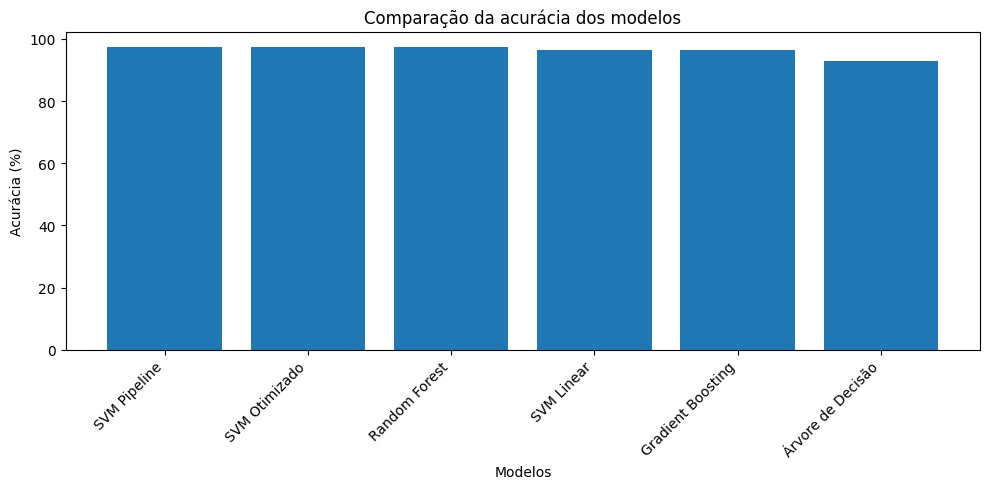

In [203]:

# Cria o gráfico de comparação
plt.figure(figsize=(10, 5))

plt.bar(
    comparacao_cancer["Modelo"],
    comparacao_cancer["Acurácia"] * 100
)

# Adiciona título e nomes dos eixos
plt.title("Comparação da acurácia dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

# Ajusta os nomes dos modelos
plt.xticks(rotation=45, ha="right")

# Exibe o gráfico
plt.tight_layout()
plt.show()


# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.967,0.965,0.965
1,SVM Pipeline,0.975,0.974,0.973
2,SVM Otimizado,0.975,0.974,0.973
3,Árvore de Decisão,0.930,0.930,0.930
4,Random Forest,0.975,0.974,0.973
5,Gradient Boosting,0.967,0.965,0.965


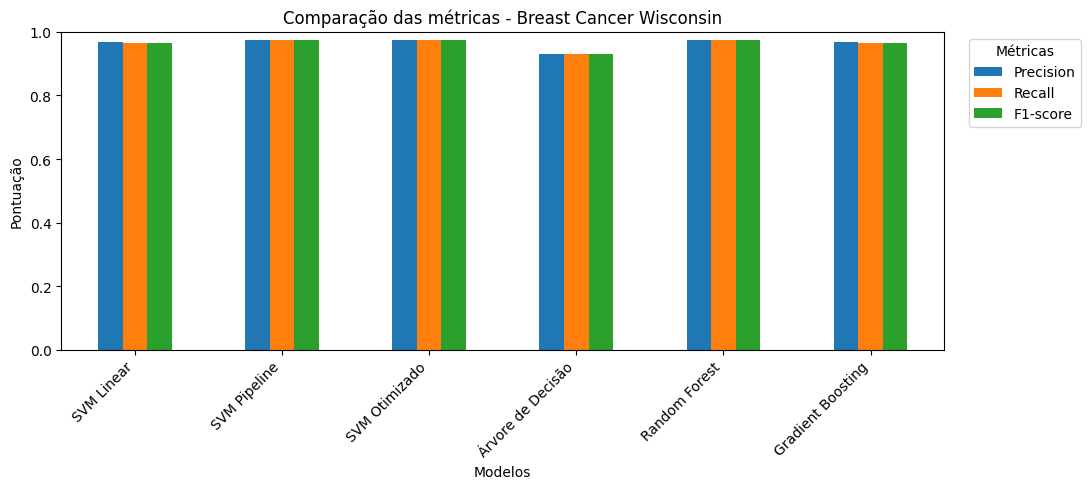

<Figure size 640x480 with 0 Axes>

In [204]:

# Calcula as métricas de classificação dos tumores
metricas_cancer = []

for nome, previsao in previsoes_cancer.items():
    metricas_cancer.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste_cancer, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste_cancer, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste_cancer, previsao, average="weighted", zero_division=0)
    })

# Organiza os resultados
df_metricas_cancer = pd.DataFrame(metricas_cancer)
display(df_metricas_cancer.round(3))

# Compara o desempenho dos modelos
df_metricas_cancer.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - Breast Cancer Wisconsin")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Depois de executar os modelos, vou identificar aquele que apresentou a maior acurácia e mostrar o resultado obtido na classificação dos tumores.

In [205]:

# Identifica os modelos com melhor desempenho
maior_acuracia = comparacao_cancer["Acurácia"].max()

melhores_modelos = comparacao_cancer[
    comparacao_cancer["Acurácia"].round(6) == round(maior_acuracia, 6)
]

print("CONCLUSÃO")
print()
print("Modelos com maior acurácia:")
print(", ".join(melhores_modelos["Modelo"]))
print("Acurácia obtida:", round(maior_acuracia * 100, 2), "%")

print()
print("Os seis modelos foram comparados na classificação")
print("de tumores benignos e malignos.")


CONCLUSÃO

Modelos com maior acurácia:
SVM Pipeline, SVM Otimizado, Random Forest
Acurácia obtida: 97.37 %

Os seis modelos foram comparados na classificação
de tumores benignos e malignos.


# Dataset 5 — Eleições Americanas de 1936
Objetivo: Classificar os percentuais de apoio a Roosevelt observados na pesquisa da Literary Digest de 1936, utilizando informações históricas de 1932.

# Passo 1 — Importação das bibliotecas
Explicação: Vou importar as bibliotecas necessárias para organizar os dados, criar gráficos, preparar as informações, treinar os modelos e avaliar os resultados.

In [206]:

# Bibliotecas para organizar e visualizar os dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ferramentas para preparação e divisão dos dados
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliação
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# Passo 2 — Carregamento do dataset
Explicação: Vou utilizar o arquivo LitDigestFull.xlsx, o mesmo do notebook original, carregando as planilhas de 1932 e 1936.

In [207]:

import pandas as pd
import os

# Localiza automaticamente o arquivo Excel
arquivos = [
    nome for nome in os.listdir("/content")
    if nome.lower().startswith("litdigestfull")
    and nome.lower().endswith(".xlsx")
]

if not arquivos:
    raise FileNotFoundError(
        "O arquivo LitDigestFull.xlsx não está na pasta /content."
    )

# Seleciona o arquivo encontrado
arquivo = os.path.join("/content", sorted(arquivos)[0])

# Carrega os dados de 1932 e 1936
df_1932 = pd.read_excel(
    arquivo,
    sheet_name="1932",
    header=1
)

df_1936 = pd.read_excel(
    arquivo,
    sheet_name="1936",
    header=1
)

print("Datasets carregados com sucesso!")

display(df_1932.head())
display(df_1936.head())


Datasets carregados com sucesso!


,Unnamed: 0,Electoral Votes,1932 Total Vote,Rep.,Dem.,Other,Did Not Vote,Unnamed: 7,Unnamed: 8,1932 Total Vote.1,...,2030,0.83,–.1,739,0.3,–.2,173235,70.61,245354,https://en.wikipedia.org/wiki/1932_United_States_presidential_election
0,ALABAMA,11.0,4272,3150,480,1,641,NaN,NaN,20161,...,2618.0,2.21,–,265.0,0.22,–,43160,36.5,118251.0,NaN
1,ARIZONA,3.0,2574,2022,218,1,333,NaN,NaN,4910,...,1269.0,0.58,–,1224.0,0.55,–,161135,73.06,220562.0,NaN
2,ARKANSAS,9.0,3712,2997,250,1,464,NaN,NaN,16225,...,63299.0,2.79,–,32608.0,1.44,–,476255,21,2267966.0,NaN
3,CALIFORNIA,22.0,81834,67017,3847,99,10871,NaN,NaN,148832,...,13591.0,2.97,–,3611.0,0.79,–,61260,13.38,457696.0,NaN
4,COLORADO,6.0,11950,9870,603,4,1473,NaN,NaN,14304,...,20480.0,3.45,–,3651.0,0.61,–,"−6,788",−1.14,594183.0,NaN


,State,Electoral Vote,Landon,Rep.,Dem.,Soc.,Others,Did Not Vote,Vote Not Indicated,Unnamed: 9,...,0.09,-.2,1397,0.51,-.3,202838,73.56,275244,AL,https://en.wikipedia.org/wiki/1936_United_States_presidential_election
0,Alabama,11,3060,1218,1298,3,3,412,126,NaN,...,0.26,-,384,0.31,-,53289.0,42.92,124163.0,AZ,NaN
1,Arizona,3,2337,1431,647,18,0,129,112,NaN,...,0.25,-,169,0.09,-,114726.0,63.94,179423.0,AR,NaN
2,Arkansas,9,2724,1338,953,7,9,274,143,NaN,...,0.43,-,24284,0.92,-,930405.0,35.26,2638882.0,CA,NaN
3,California,22,89516,65360,16200,315,53,3519,4069,NaN,...,0.33,-,841,0.17,-,113754.0,23.28,488684.0,CO,NaN
4,Colorado,6,15949,11872,2714,131,12,637,583,NaN,...,0.82,-,2421,0.35,-,103444.0,14.98,690723.0,CT,NaN


# Passo 3 — Conhecendo os dados
Explicação: Vou verificar o tamanho dos datasets, os nomes das colunas e os valores ausentes para compreender melhor a organização dos dados.

In [208]:

# Mostra o tamanho dos datasets
print("Dataset 1932:", df_1932.shape)
print("Dataset 1936:", df_1936.shape)

# Mostra as colunas
print("\nColunas de 1932:")
print(df_1932.columns.tolist())

print("\nColunas de 1936:")
print(df_1936.columns.tolist())

# Verifica valores ausentes
print("\nValores ausentes em 1932:")
print(df_1932.isnull().sum())

print("\nValores ausentes em 1936:")
print(df_1936.isnull().sum())


Dataset 1932: (51, 45)
Dataset 1936: (50, 56)

Colunas de 1932:
['Unnamed: 0', 'Electoral Votes', '1932 Total Vote', 'Rep.', 'Dem.', 'Other', 'Did Not Vote', 'Unnamed: 7', 'Unnamed: 8', '1932 Total Vote.1', 'Rep..1', 'Dem..1', 'Other.1', 'Did Not Vote.1', 'Unnamed: 14', 'Unnamed: 15', 'Thomas', 'Reynolds', 'Coxey', 'Upshaw', 'Foster', 'Miscellaneous', 'Totals', 'Unnamed: 23', 'Total', 'Unnamed: 25', 'Unnamed: 26', 'Alabama', 11, 207910, 84.74, '11.1', 34675, 14.13, '–', 2030, 0.83, '–.1', 739, 0.3, '–.2', 173235, 70.61, 245354, 'https://en.wikipedia.org/wiki/1932_United_States_presidential_election']

Colunas de 1936:
['State', 'Electoral Vote', 'Landon   ', 'Rep.', 'Dem.', 'Soc.', 'Others', 'Did Not Vote', 'Vote Not Indicated', 'Unnamed: 9', 'Roosevelt (D)', 'Rep..1', 'Dem..1', 'Soc..1', 'Others.1', 'Did Note Vote', 'Vote Not Indicated.1', 'Unnamed: 17', 'Lemke', 'Rep..2', 'Dem..2', 'Soc..2', 'Others.2', 'Did Not Vote.1', 'Vote Not Indicated.2', 'Unnamed: 25', 'Thomas', 'Browder', 'Co

## Passo 4 — Preparação dos dados para classificação
Explicação: Vou organizar os dados de 1932 e 1936, somar os registros históricos das categorias de voto e juntar as informações por estado. Depois, vou criar a classificação de Roosevelt, considerando os percentuais da pesquisa abaixo ou acima de 50%.

In [209]:

# Cria cópias das bases originais
dados_1932 = df_1932.copy()
dados_1936 = df_1936.copy()

# Organiza a coluna dos estados
dados_1932.rename(
    columns={dados_1932.columns[0]: "estado"},
    inplace=True
)

dados_1936.rename(
    columns={"State": "estado"},
    inplace=True
)

# Padroniza os nomes dos estados
for dados in [dados_1932, dados_1936]:
    dados["estado"] = (
        dados["estado"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    dados.drop_duplicates(
        subset="estado",
        inplace=True
    )

# Soma os registros históricos das duas candidaturas
dados_1932["rep_1932"] = (
    pd.to_numeric(dados_1932["Rep."], errors="coerce") +
    pd.to_numeric(dados_1932["Rep..1"], errors="coerce")
)

dados_1932["dem_1932"] = (
    pd.to_numeric(dados_1932["Dem."], errors="coerce") +
    pd.to_numeric(dados_1932["Dem..1"], errors="coerce")
)

dados_1932["outros_1932"] = (
    pd.to_numeric(dados_1932["Other"], errors="coerce") +
    pd.to_numeric(dados_1932["Other.1"], errors="coerce")
)

dados_1932["nao_votou_1932"] = (
    pd.to_numeric(dados_1932["Did Not Vote"], errors="coerce") +
    pd.to_numeric(dados_1932["Did Not Vote.1"], errors="coerce")
)

# Converte os votos de 1936 para números
dados_1936["Roosevelt (D)"] = pd.to_numeric(
    dados_1936["Roosevelt (D)"],
    errors="coerce"
)

dados_1936["Total"] = pd.to_numeric(
    dados_1936["Total"],
    errors="coerce"
)

# Seleciona as características de 1932
variaveis_eleicoes = [
    "rep_1932",
    "dem_1932",
    "outros_1932",
    "nao_votou_1932"
]

# Junta as informações dos dois anos
dados_eleicoes = pd.merge(
    dados_1932[["estado"] + variaveis_eleicoes],
    dados_1936[["estado", "Roosevelt (D)", "Total"]],
    on="estado",
    how="inner",
    validate="one_to_one"
)

# Mantém somente registros com total válido
dados_eleicoes = dados_eleicoes[
    dados_eleicoes["Total"] > 0
].copy()

# Calcula o percentual de Roosevelt na pesquisa
dados_eleicoes["pct_roosevelt"] = (
    dados_eleicoes["Roosevelt (D)"] /
    dados_eleicoes["Total"]
) * 100

# Remove registros incompletos
dados_eleicoes = dados_eleicoes.dropna(
    subset=variaveis_eleicoes + ["pct_roosevelt"]
)

# Cria as classes
# 0 = abaixo de 50%
# 1 = 50% ou mais
dados_eleicoes["classe_roosevelt"] = (
    dados_eleicoes["pct_roosevelt"] >= 50
).astype(int)

# Separa as características e a classificação
X_eleicoes = dados_eleicoes[variaveis_eleicoes]
y_eleicoes = dados_eleicoes["classe_roosevelt"]

print("Dados preparados com sucesso!")
print("Quantidade de registros:", len(dados_eleicoes))

print("\nDistribuição das classes:")
print(y_eleicoes.value_counts().sort_index())

display(dados_eleicoes.head())


Dados preparados com sucesso!
Quantidade de registros: 49

Distribuição das classes:
classe_roosevelt
0    34
1    15
Name: count, dtype: int64


,estado,rep_1932,dem_1932,outros_1932,nao_votou_1932,Roosevelt (D),Total,pct_roosevelt,classe_roosevelt
0,ALABAMA,6333,14109,5,3986,10082,13273,75.958713,1
1,ARIZONA,3619,2799,3,1063,1975,4476,44.124218,0
2,ARKANSAS,5411,11814,6,2706,7608,10540,72.182163,1
3,CALIFORNIA,144214,54099,439,31914,77245,173935,44.410268,0
4,COLORADO,15600,7011,36,3607,10025,26786,37.426267,0


# Passo 4.1 — Análise exploratória dos dados
Explicação: Vou criar um gráfico para visualizar a quantidade de estados em cada categoria de apoio a Roosevelt na pesquisa de 1936.

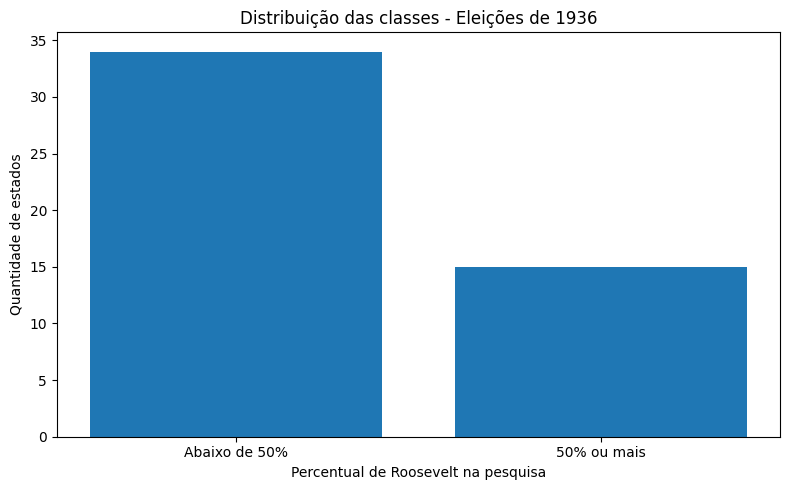

In [210]:

# Conta os registros por classe
contagem = y_eleicoes.value_counts().reindex(
    [0, 1], fill_value=0
)

# Cria o gráfico
plt.figure(figsize=(8, 5))

plt.bar(
    ["Abaixo de 50%", "50% ou mais"],
    contagem.values
)

plt.title("Distribuição das classes - Eleições de 1936")
plt.xlabel("Percentual de Roosevelt na pesquisa")
plt.ylabel("Quantidade de estados")

plt.tight_layout()
plt.show()


# Passo 5 — Divisão entre treino e teste
Explicação: Vou separar 80% dos dados para treinamento e 20% para teste, mantendo a proporção das classes.

In [211]:

# Divide os dados em treino e teste
X_treino_eleicoes, X_teste_eleicoes, y_treino_eleicoes, y_teste_eleicoes = train_test_split(
    X_eleicoes,
    y_eleicoes,
    test_size=0.2,
    random_state=42,
    stratify=y_eleicoes
)

print("Dados de treino:", X_treino_eleicoes.shape)
print("Dados de teste:", X_teste_eleicoes.shape)


Dados de treino: (39, 4)
Dados de teste: (10, 4)


# Passo 6 — Treinamento dos modelos e otimização do SVM
Explicação: Vou treinar os seis modelos de classificação e utilizar o GridSearchCV para encontrar os melhores parâmetros do SVM.

In [212]:

# Cria o SVM para otimização
svm_base = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC()
)

# Define os parâmetros
parametros = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Configura a otimização
grid_eleicoes = GridSearchCV(
    svm_base,
    parametros,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Organiza os seis modelos
modelos_eleicoes = {
    "SVM Linear": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear")
    ),

    "SVM Pipeline": make_pipeline(
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_eleicoes,

    "Árvore de Decisão": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Guarda as previsões
previsoes_eleicoes = {}

# Treina e testa os modelos
for nome, modelo in modelos_eleicoes.items():

    print("Treinando:", nome)

    modelo.fit(
        X_treino_eleicoes,
        y_treino_eleicoes
    )

    previsoes_eleicoes[nome] = modelo.predict(
        X_teste_eleicoes
    )

# Mostra os melhores parâmetros
print("\nMelhores parâmetros do SVM:")
print(grid_eleicoes.best_params_)


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM:
{'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}


# Passo 7 — Avaliação dos resultados
Explicação: Vou calcular a acurácia de cada modelo, apresentar o relatório de classificação e criar as matrizes de confusão para visualizar os acertos e erros.


Modelo: SVM Linear
Acurácia: 70.0 %
              precision    recall  f1-score   support

           0       0.75      0.86      0.80         7
           1       0.50      0.33      0.40         3

    accuracy                           0.70        10
   macro avg       0.62      0.60      0.60        10
weighted avg       0.68      0.70      0.68        10


Modelo: SVM Pipeline
Acurácia: 70.0 %
              precision    recall  f1-score   support

           0       0.75      0.86      0.80         7
           1       0.50      0.33      0.40         3

    accuracy                           0.70        10
   macro avg       0.62      0.60      0.60        10
weighted avg       0.68      0.70      0.68        10


Modelo: SVM Otimizado
Acurácia: 70.0 %
              precision    recall  f1-score   support

           0       0.83      0.71      0.77         7
           1       0.50      0.67      0.57         3

    accuracy                           0.70        10
   macro avg

,Modelo,Acurácia
4,Random Forest,0.8
3,Árvore de Decisão,0.8
5,Gradient Boosting,0.8
0,SVM Linear,0.7
1,SVM Pipeline,0.7
2,SVM Otimizado,0.7


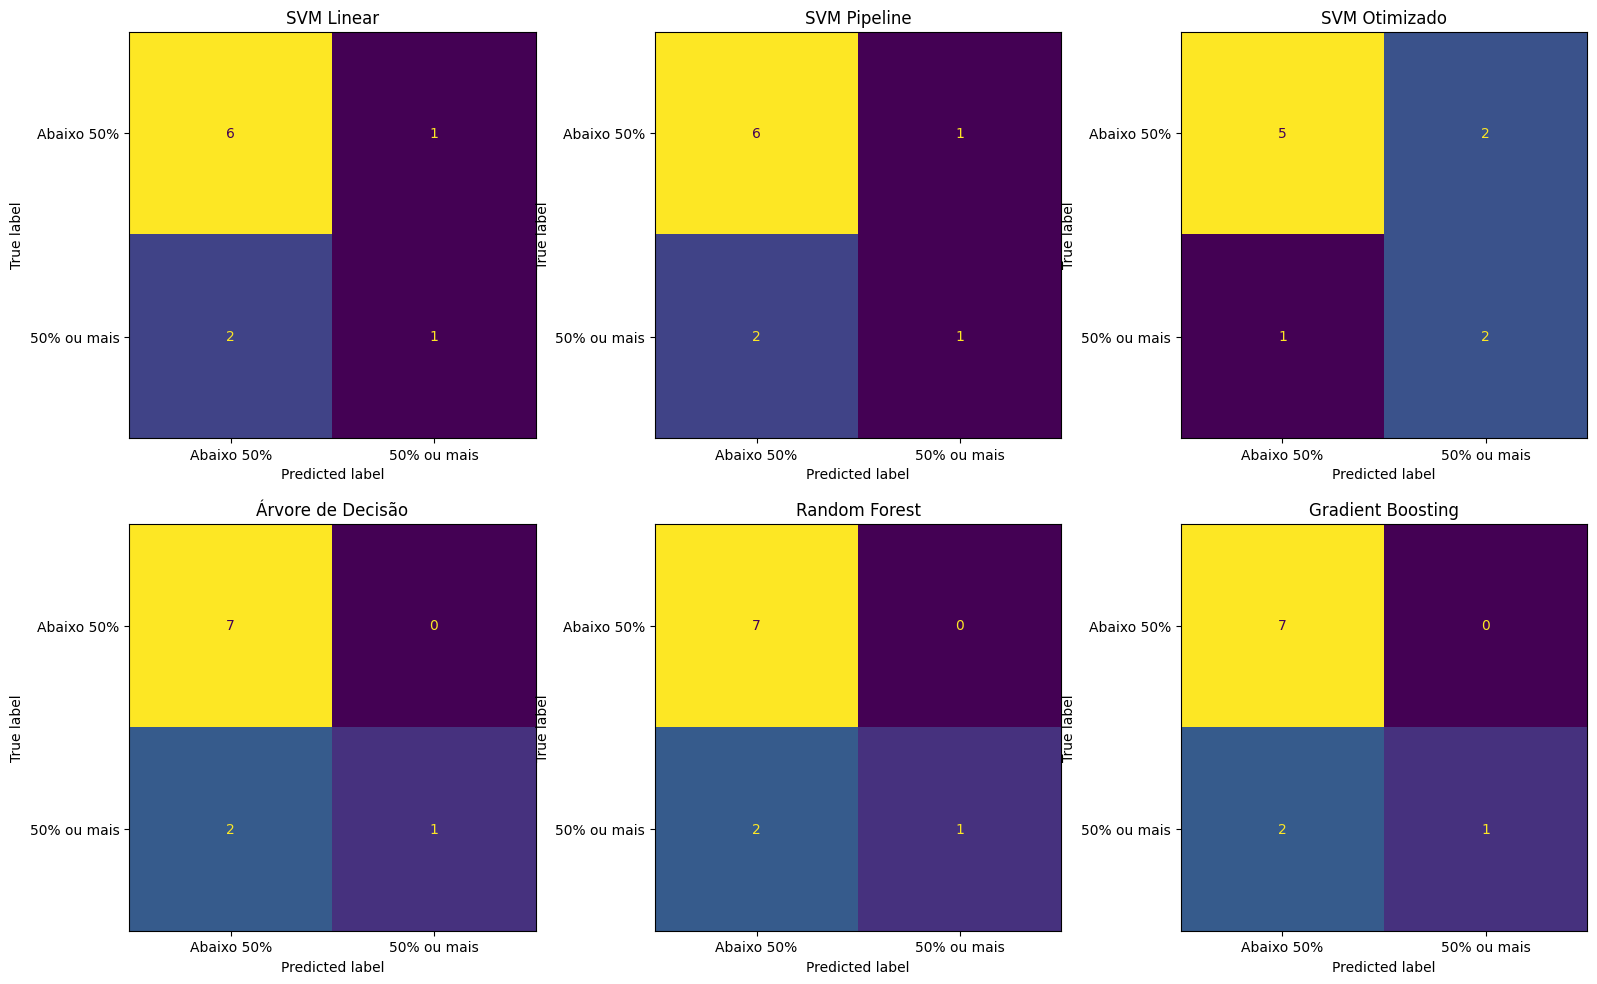

In [213]:

# Guarda os resultados
resultados_eleicoes = []

# Avalia os modelos
for nome, previsao in previsoes_eleicoes.items():

    acuracia = accuracy_score(
        y_teste_eleicoes,
        previsao
    )

    resultados_eleicoes.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    print("\nModelo:", nome)
    print("Acurácia:", round(acuracia * 100, 2), "%")

    print(
        classification_report(
            y_teste_eleicoes,
            previsao,
            labels=[0, 1],
            zero_division=0
        )
    )

# Organiza a comparação
comparacao_eleicoes = pd.DataFrame(
    resultados_eleicoes
)

comparacao_eleicoes = comparacao_eleicoes.sort_values(
    by="Acurácia",
    ascending=False
)

print("\nComparação dos modelos:")
display(comparacao_eleicoes)

# Cria as matrizes de confusão
fig, eixos = plt.subplots(2, 3, figsize=(16, 10))

for eixo, (nome, previsao) in zip(
    eixos.flatten(),
    previsoes_eleicoes.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_teste_eleicoes,
        previsao,
        labels=[0, 1],
        display_labels=["Abaixo 50%", "50% ou mais"],
        ax=eixo,
        colorbar=False
    )

    eixo.set_title(nome)

plt.tight_layout()
plt.show()


# Gráfico de barras — Comparação dos modelos
Explicação: Vou comparar a acurácia dos seis modelos para identificar qual apresentou o melhor desempenho no conjunto de teste.

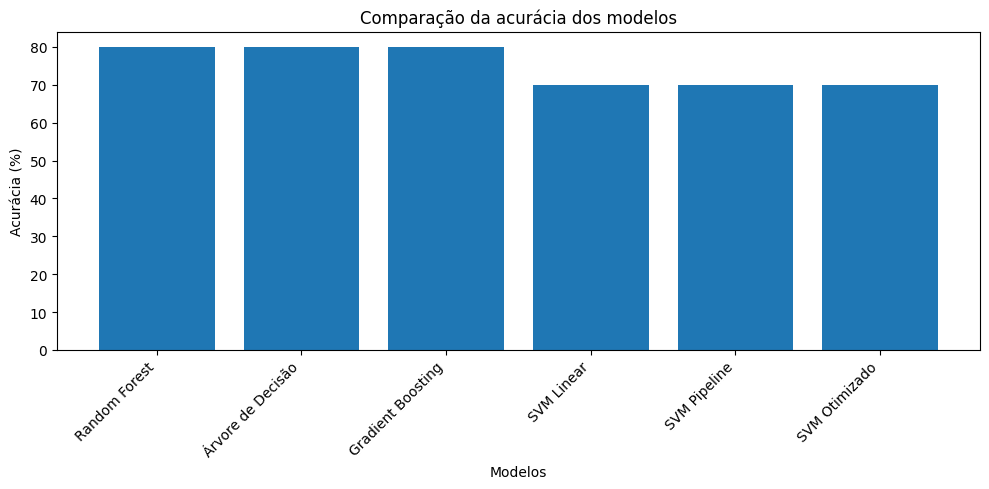

In [214]:

# Cria o gráfico de comparação
plt.figure(figsize=(10, 5))

plt.bar(
    comparacao_eleicoes["Modelo"],
    comparacao_eleicoes["Acurácia"] * 100
)

plt.title("Comparação da acurácia dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.675,0.7,0.680
1,SVM Pipeline,0.675,0.7,0.680
2,SVM Otimizado,0.733,0.7,0.710
3,Árvore de Decisão,0.844,0.8,0.762
4,Random Forest,0.844,0.8,0.762
5,Gradient Boosting,0.844,0.8,0.762


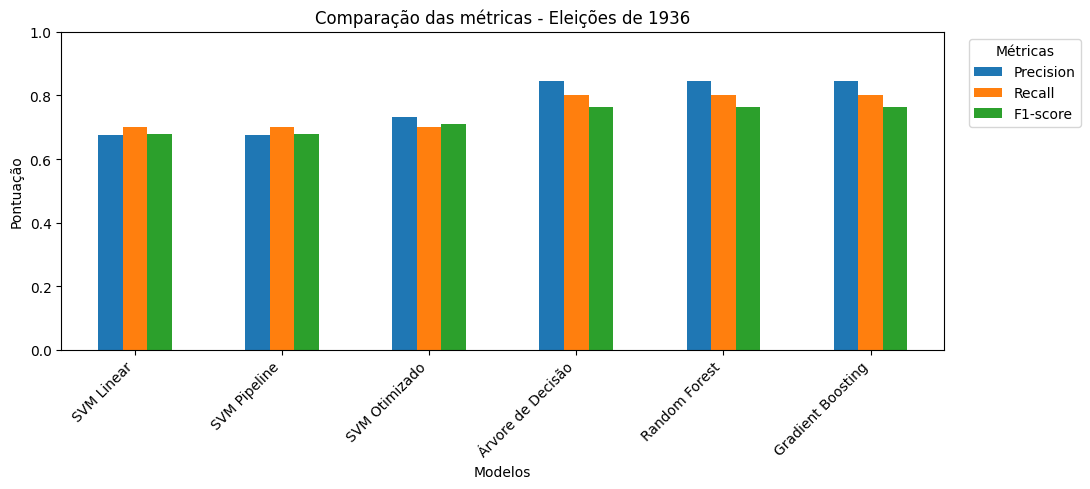

<Figure size 640x480 with 0 Axes>

In [215]:

# Calcula as métricas dos modelos eleitorais
metricas_eleicoes = []

for nome, previsao in previsoes_eleicoes.items():
    metricas_eleicoes.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste_eleicoes, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste_eleicoes, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste_eleicoes, previsao, average="weighted", zero_division=0)
    })

# Organiza os resultados
df_metricas_eleicoes = pd.DataFrame(metricas_eleicoes)
display(df_metricas_eleicoes.round(3))

# Compara os seis modelos
df_metricas_eleicoes.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - Eleições de 1936")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Vou identificar o modelo com a maior acurácia e apresentar o resultado final da classificação.

Como o conjunto de teste possui apenas dez registros, os resultados devem ser interpretados com cautela. A acurácia de 80% representa oito classificações corretas nesse conjunto. Além disso, esta análise utiliza algoritmos de classificação aplicados aos dados históricos, mas não representa uma correção completa do viés de amostragem da pesquisa Literary Digest de 1936.

In [216]:

# Identifica todos os modelos empatados
maior_acuracia = comparacao_eleicoes["Acurácia"].max()

melhores_modelos = comparacao_eleicoes[
    comparacao_eleicoes["Acurácia"].round(6) == round(maior_acuracia, 6)
]

print("CONCLUSÃO")
print("-" * 40)

print("Modelos com maior acurácia:")
print(", ".join(melhores_modelos["Modelo"]))
print("Acurácia obtida:", round(maior_acuracia * 100, 2), "%")





CONCLUSÃO
----------------------------------------
Modelos com maior acurácia:
Random Forest, Árvore de Decisão, Gradient Boosting
Acurácia obtida: 80.0 %


# Dataset 6 — Heart Dataset
Tema: Classificação de doenças cardíacas

Fonte: Heart Dataset — Kaggle

Objetivo: Utilizar algoritmos de Machine Learning para classificar a presença ou ausência de doença cardíaca, comparando o desempenho de seis modelos: SVM Linear, SVM Pipeline, SVM Otimizado, Árvore de Decisão, Random Forest e Gradient Boosting.



#  Passo 1 — Importação das bibliotecas
Explicação: Vou importar as bibliotecas necessárias para organizar os dados, criar gráficos, preparar as informações, treinar os modelos e avaliar os resultados.

In [217]:

# Bibliotecas para organizar e visualizar os dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ferramentas para preparar e dividir os dados
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Modelos de classificação
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Ferramentas para avaliar os resultados
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# Passo 2 — Carregamento do dataset
Explicação: Vou baixar o Heart Dataset diretamente do Kaggle e verificar quais arquivos estão disponíveis antes de carregar os dados.

In [218]:

# Instala o KaggleHub
!pip install -q kagglehub

import kagglehub
import pandas as pd
import os

# Baixa o dataset do Kaggle
path = kagglehub.dataset_download(
    "mfarhaannazirkhan/heart-dataset"
)

# Localiza o arquivo com os dados tratados
arquivo = os.path.join(
    path,
    "cleaned_merged_heart_dataset.csv"
)

# Carrega o dataset
df_heart = pd.read_csv(arquivo)

# Mostra as informações iniciais
print("Dataset carregado com sucesso!")
print("Quantidade de linhas e colunas:", df_heart.shape)

print("\nColunas disponíveis:")
print(df_heart.columns.tolist())

# Mostra as primeiras linhas
display(df_heart.head())


Using Colab cache for faster access to the 'heart-dataset' dataset.
Dataset carregado com sucesso!
Quantidade de linhas e colunas: (1888, 14)

Colunas disponíveis:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# Passo 3 — Conhecendo os dados
Explicação: Vou verificar o tamanho do dataset, os nomes das colunas, os tipos de dados e os valores ausentes para compreender sua estrutura.

In [219]:

# Mostra a quantidade de linhas e colunas
print("Tamanho do dataset:", df_heart.shape)

# Mostra os nomes das colunas
print("\nColunas:")
print(df_heart.columns.tolist())

# Mostra os tipos de dados
print("\nInformações gerais:")
df_heart.info()

# Verifica valores ausentes
print("\nValores ausentes:")
print(df_heart.isnull().sum())

# Mostra as primeiras linhas
display(df_heart.head())


Tamanho do dataset: (1888, 14)

Colunas:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   int64  
 1   sex       1888 non-null   int64  
 2   cp        1888 non-null   int64  
 3   trestbps  1888 non-null   int64  
 4   chol      1888 non-null   int64  
 5   fbs       1888 non-null   int64  
 6   restecg   1888 non-null   int64  
 7   thalachh  1888 non-null   int64  
 8   exang     1888 non-null   int64  
 9   oldpeak   1888 non-null   float64
 10  slope     1888 non-null   int64  
 11  ca        1888 non-null   int64  
 12  thal      1888 non-null   int64  
 13  target    1888 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 206.6 KB

Valores ausentes:
age        

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# Passo 4 — Preparação dos dados para classificação
Explicação: Vou identificar a coluna que representa a condição cardíaca, separar as características dos pacientes e transformar as colunas de texto em valores numéricos para os modelos.


In [220]:

# Organiza os nomes das colunas
df_heart.columns = df_heart.columns.str.strip()

# Procura a coluna de classificação
possiveis_alvos = [
    "HeartDisease",
    "Heart Disease",
    "target",
    "Target",
    "HeartDiseaseStatus",
    "Heart Disease Status",
    "num"
]

coluna_alvo = next(
    (col for col in possiveis_alvos if col in df_heart.columns),
    None
)

if coluna_alvo is None:
    raise ValueError(
        "Coluna alvo não identificada. "
        f"Confira as colunas: {df_heart.columns.tolist()}"
    )

# Cria uma cópia dos dados
dados_heart = df_heart.copy()

# Remove registros sem classificação
dados_heart = dados_heart.dropna(
    subset=[coluna_alvo]
)

# Separa características e classificação
X_heart = dados_heart.drop(columns=[coluna_alvo])
y_heart = dados_heart[coluna_alvo]

# Remove identificadores, quando existirem
X_heart = X_heart.drop(
    columns=["id", "ID", "Patient ID", "PatientID"],
    errors="ignore"
)

# Transforma colunas de texto em números
X_heart = pd.get_dummies(
    X_heart,
    dtype=int
)

# Converte características numéricas quando possível
for coluna in X_heart.columns:
    X_heart[coluna] = pd.to_numeric(
        X_heart[coluna],
        errors="coerce"
    )

# Converte a classificação em categorias numéricas
# Para a coluna num, 0 indica ausência e >0 presença
if coluna_alvo == "num":
    y_heart = (
        pd.to_numeric(y_heart, errors="coerce") > 0
    ).astype(int)
else:
    y_heart = y_heart.astype(str).str.strip().str.lower()

    mapa = {
        "0": 0, "1": 1,
        "no": 0, "yes": 1,
        "false": 0, "true": 1,
        "absent": 0, "present": 1,
        "negative": 0, "positive": 1
    }

    y_heart = y_heart.map(mapa)

    if y_heart.isna().any():
        raise ValueError(
            "Existem valores de classificação não reconhecidos. "
            "Confira os valores originais da coluna alvo."
        )

    y_heart = y_heart.astype(int)

# Mostra a distribuição
print("Coluna utilizada:", coluna_alvo)
print("\nDistribuição das classes:")
print(y_heart.value_counts().sort_index())

print("\nQuantidade de características:", X_heart.shape[1])

display(X_heart.head())


Coluna utilizada: target

Distribuição das classes:
target
0    911
1    977
Name: count, dtype: int64

Quantidade de características: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


# Passo 4.1 — Verificação e remoção de registros duplicados

Explicação: Vou verificar se existem registros repetidos no dataset e removê-los antes de dividir os dados entre treinamento e teste, evitando que informações duplicadas influenciem a avaliação dos modelos.

In [221]:

# Junta as características e a classificação
dados_sem_duplicatas = X_heart.copy()
dados_sem_duplicatas["target"] = y_heart.to_numpy()

# Verifica quantos registros estão repetidos
duplicados = dados_sem_duplicatas.duplicated().sum()

print("Total de registros:", len(dados_sem_duplicatas))
print("Registros duplicados:", duplicados)

# Remove os registros duplicados
dados_sem_duplicatas = dados_sem_duplicatas.drop_duplicates().copy()

# Separa novamente as características e a classificação
X_heart = dados_sem_duplicatas.drop(columns=["target"])
y_heart = dados_sem_duplicatas["target"]

print("\nApós a limpeza:")
print("Registros restantes:", len(dados_sem_duplicatas))
print("Registros removidos:", duplicados)

print("\nDistribuição das classes:")
print(y_heart.value_counts())


Total de registros: 1888
Registros duplicados: 1286

Após a limpeza:
Registros restantes: 602
Registros removidos: 1286

Distribuição das classes:
target
0    310
1    292
Name: count, dtype: int64


# Passo 4.2 — Análise exploratória dos dados
Explicação: Vou visualizar a quantidade de registros classificados com e sem doença cardíaca, verificando a distribuição das classes.

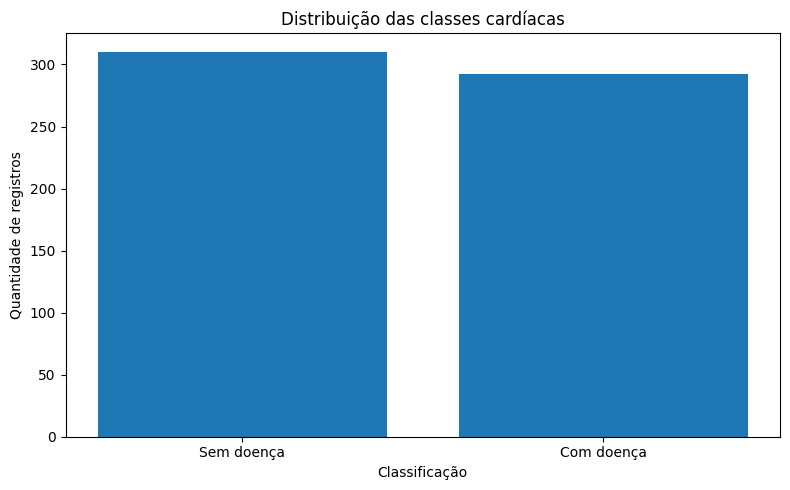

In [222]:

# Conta os registros por classe
contagem = y_heart.value_counts().reindex(
    [0, 1], fill_value=0
)

# Cria o gráfico
plt.figure(figsize=(8, 5))

plt.bar(
    ["Sem doença", "Com doença"],
    contagem.values
)

plt.title("Distribuição das classes cardíacas")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de registros")

plt.tight_layout()
plt.show()


# Passo 4.3 — Matriz de correlação
Explicação: Vou analisar as relações entre as características dos pacientes e a classificação cardíaca por meio de uma matriz de correlação.

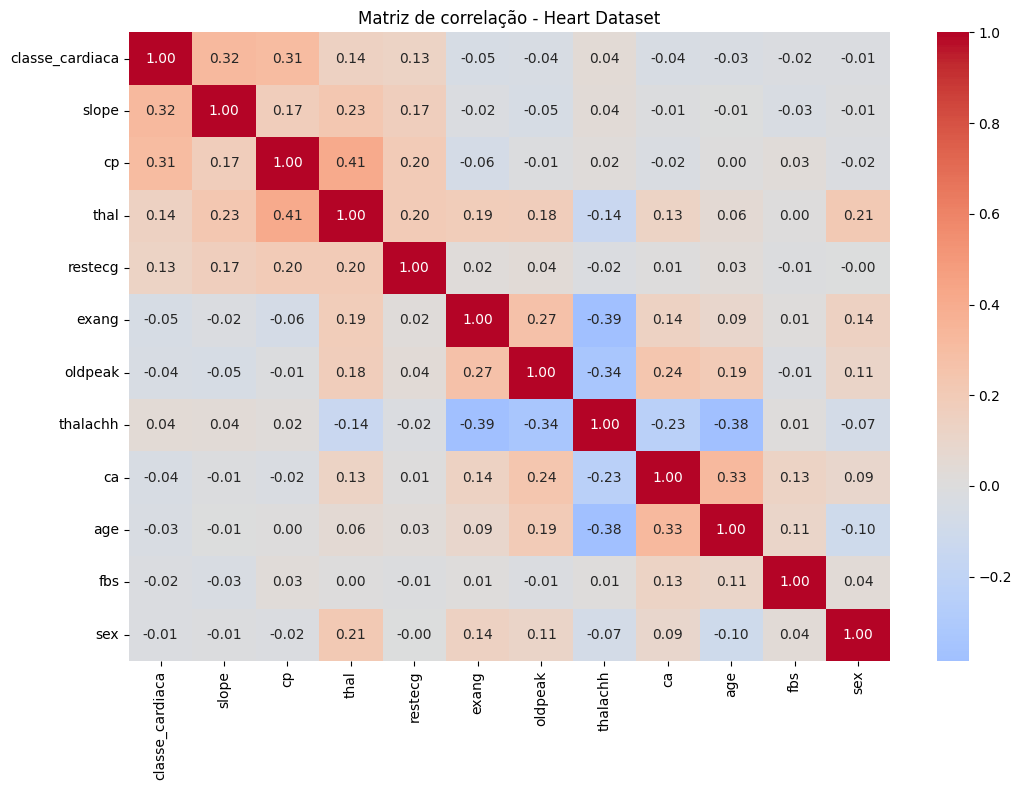

In [223]:

# Junta as características e a classificação
dados_correlacao = X_heart.copy()
dados_correlacao["classe_cardiaca"] = y_heart.values

# Calcula a correlação
correlacao = dados_correlacao.corr(numeric_only=True)

# Seleciona as variáveis mais relacionadas à classificação
principais = (
    correlacao["classe_cardiaca"]
    .abs()
    .sort_values(ascending=False)
    .head(12)
    .index
)

# Cria o mapa de calor
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlacao.loc[principais, principais],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlação - Heart Dataset")
plt.tight_layout()
plt.show()


# Passo 5 — Divisão entre treino e teste
Explicação: Vou separar 80% dos registros para treinamento e 20% para teste, mantendo a proporção das classes.

In [224]:

# Verifica se existem duas classes
if y_heart.nunique() != 2:
    raise ValueError(
        "A classificação precisa conter duas classes."
    )

# Divide os dados
X_treino_heart, X_teste_heart, y_treino_heart, y_teste_heart = train_test_split(
    X_heart,
    y_heart,
    test_size=0.2,
    random_state=42,
    stratify=y_heart
)

print("Dados de treino:", X_treino_heart.shape)
print("Dados de teste:", X_teste_heart.shape)


Dados de treino: (481, 13)
Dados de teste: (121, 13)


# Passo 6 — Treinamento dos seis modelos
Explicação: Vou treinar os mesmos seis modelos utilizados nos outros datasets. O SVM Otimizado utilizará o GridSearchCV para encontrar os melhores parâmetros.

In [225]:

# Cria o SVM para otimização
svm_base_heart = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC()
)

# Define os parâmetros
parametros_heart = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    },
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", "auto"]
    }
]

# Configura o GridSearchCV
grid_heart = GridSearchCV(
    svm_base_heart,
    parametros_heart,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Organiza os modelos
modelos_heart = {
    "SVM Linear": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel="linear")
    ),

    "SVM Pipeline": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "SVM Otimizado": grid_heart,

    "Árvore de Decisão": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

# Guarda as previsões
previsoes_heart = {}

# Treina e testa cada modelo
for nome, modelo in modelos_heart.items():

    print("Treinando:", nome)

    modelo.fit(X_treino_heart, y_treino_heart)

    previsoes_heart[nome] = modelo.predict(
        X_teste_heart
    )

# Mostra os melhores parâmetros
print("\nMelhores parâmetros do SVM:")
print(grid_heart.best_params_)

print("\nAcurácia na validação cruzada:")
print(round(grid_heart.best_score_ * 100, 2), "%")


Treinando: SVM Linear
Treinando: SVM Pipeline
Treinando: SVM Otimizado
Treinando: Árvore de Decisão
Treinando: Random Forest
Treinando: Gradient Boosting

Melhores parâmetros do SVM:
{'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Acurácia na validação cruzada:
73.4 %


# Passo 7 — Avaliação dos resultados
Explicação: Vou calcular a acurácia dos modelos, apresentar os relatórios de classificação e criar as matrizes de confusão para visualizar os acertos e erros.


Modelo: SVM Linear
Acurácia: 70.25 %
              precision    recall  f1-score   support

  Sem doença       0.72      0.68      0.70        62
  Com doença       0.68      0.73      0.70        59

    accuracy                           0.70       121
   macro avg       0.70      0.70      0.70       121
weighted avg       0.70      0.70      0.70       121


Modelo: SVM Pipeline
Acurácia: 76.86 %
              precision    recall  f1-score   support

  Sem doença       0.77      0.77      0.77        62
  Com doença       0.76      0.76      0.76        59

    accuracy                           0.77       121
   macro avg       0.77      0.77      0.77       121
weighted avg       0.77      0.77      0.77       121


Modelo: SVM Otimizado
Acurácia: 76.86 %
              precision    recall  f1-score   support

  Sem doença       0.77      0.77      0.77        62
  Com doença       0.76      0.76      0.76        59

    accuracy                           0.77       121
   macro 

,Modelo,Acurácia
4,Random Forest,0.809917
5,Gradient Boosting,0.801653
2,SVM Otimizado,0.768595
1,SVM Pipeline,0.768595
0,SVM Linear,0.702479
3,Árvore de Decisão,0.644628


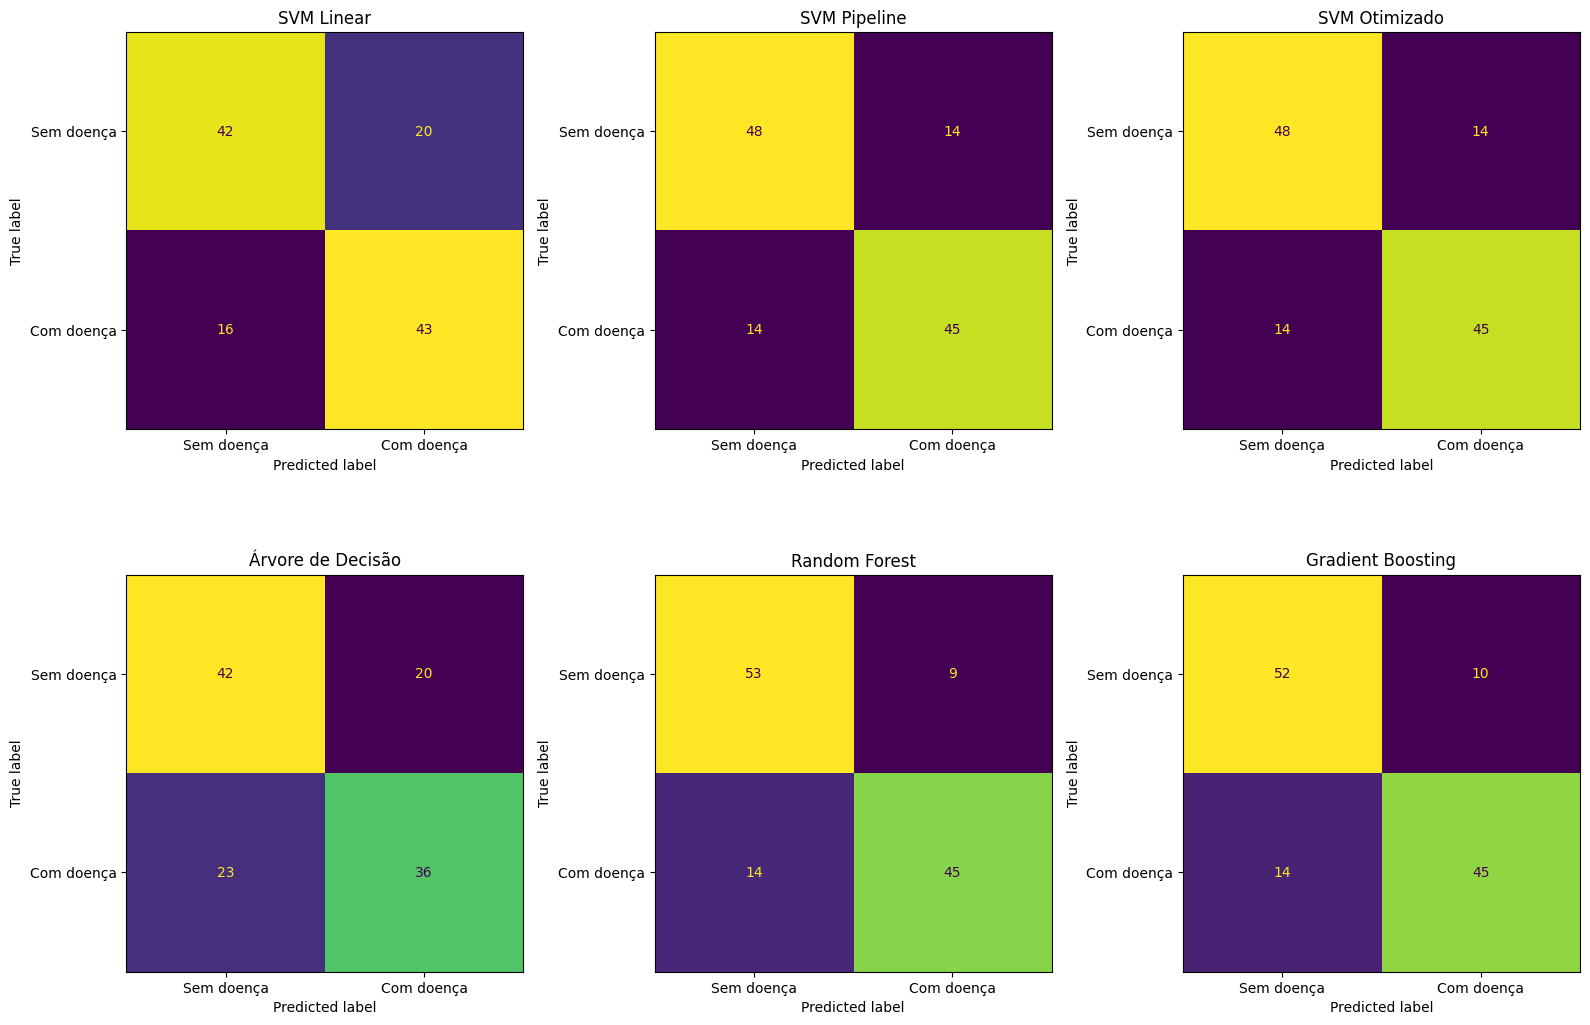

In [226]:

# Lista para guardar os resultados
resultados_heart = []

# Avalia cada modelo
for nome, previsao in previsoes_heart.items():

    acuracia = accuracy_score(
        y_teste_heart,
        previsao
    )

    resultados_heart.append({
        "Modelo": nome,
        "Acurácia": acuracia
    })

    print("\nModelo:", nome)
    print("Acurácia:", round(acuracia * 100, 2), "%")

    print(
        classification_report(
            y_teste_heart,
            previsao,
            labels=[0, 1],
            target_names=["Sem doença", "Com doença"],
            zero_division=0
        )
    )

# Organiza a comparação
comparacao_heart = pd.DataFrame(resultados_heart)

comparacao_heart = comparacao_heart.sort_values(
    by="Acurácia",
    ascending=False
)

print("\nCOMPARAÇÃO DOS MODELOS")
display(comparacao_heart)

# Cria as matrizes de confusão
fig, eixos = plt.subplots(2, 3, figsize=(16, 11))

for eixo, (nome, previsao) in zip(
    eixos.flatten(),
    previsoes_heart.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_teste_heart,
        previsao,
        labels=[0, 1],
        display_labels=["Sem doença", "Com doença"],
        ax=eixo,
        colorbar=False
    )

    eixo.set_title(nome)

plt.tight_layout()
plt.show()


# Gráfico de barras — Comparação dos modelos
Explicação: Vou criar um gráfico para comparar a acurácia dos seis modelos, mostrando qual apresentou o melhor desempenho.

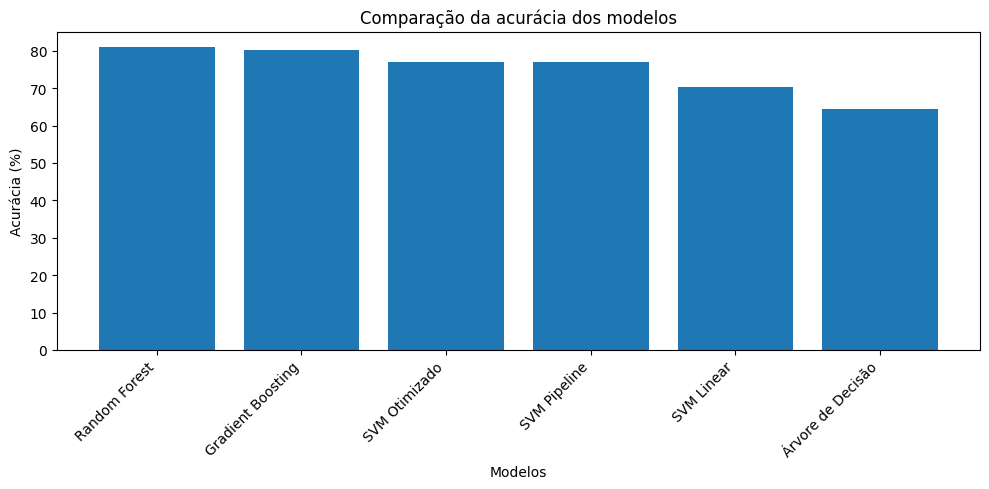

In [227]:

# Cria o gráfico de comparação
plt.figure(figsize=(10, 5))

plt.bar(
    comparacao_heart["Modelo"],
    comparacao_heart["Acurácia"] * 100
)

plt.title("Comparação da acurácia dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


# Passo 7.1 — Comparação de Precision, Recall e F1-score

Nesta etapa, vou comparar as métricas Precision, Recall e F1-score dos seis modelos utilizados. Essas métricas complementam a acurácia e ajudam a identificar as diferenças no desempenho dos algoritmos de classificação.

,Modelo,Precision,Recall,F1-score
0,SVM Linear,0.704,0.702,0.702
1,SVM Pipeline,0.769,0.769,0.769
2,SVM Otimizado,0.769,0.769,0.769
3,Árvore de Decisão,0.645,0.645,0.644
4,Random Forest,0.812,0.810,0.809
5,Gradient Boosting,0.803,0.802,0.801


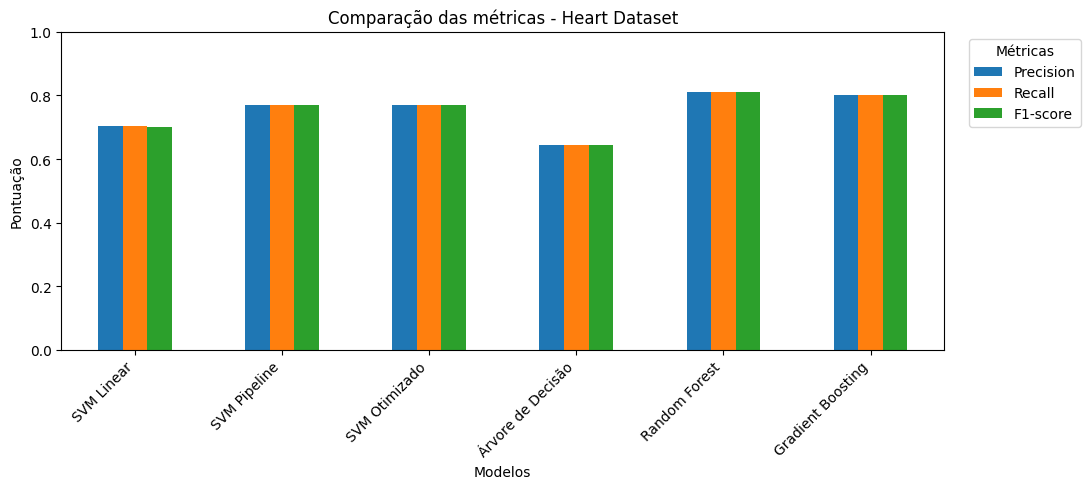

<Figure size 640x480 with 0 Axes>

In [228]:

# Calcula as métricas dos modelos de doenças cardíacas
metricas_heart = []

for nome, previsao in previsoes_heart.items():
    metricas_heart.append({
        "Modelo": nome,
        "Precision": precision_score(y_teste_heart, previsao, average="weighted", zero_division=0),
        "Recall": recall_score(y_teste_heart, previsao, average="weighted", zero_division=0),
        "F1-score": f1_score(y_teste_heart, previsao, average="weighted", zero_division=0)
    })

# Organiza os resultados
df_metricas_heart = pd.DataFrame(metricas_heart)
display(df_metricas_heart.round(3))

# Compara os seis modelos
df_metricas_heart.set_index("Modelo").plot(kind="bar", figsize=(11, 5))
plt.title("Comparação das métricas - Heart Dataset")
plt.xlabel("Modelos")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
# Posiciona a legenda fora da área do gráfico
plt.legend(
    title="Métricas",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()


# Passo 8 — Conclusão
Explicação: Vou identificar o modelo com a maior acurácia e apresentar o resultado final da classificação de doenças cardíacas.

In [229]:

# Identifica o modelo com maior acurácia
melhor_modelo_heart = comparacao_heart.loc[
    comparacao_heart["Acurácia"].idxmax()
]

print("CONCLUSÃO")
print("-" * 40)

print(
    "Modelo com maior acurácia:",
    melhor_modelo_heart["Modelo"]
)

print(
    "Acurácia obtida:",
    round(melhor_modelo_heart["Acurácia"] * 100, 2),
    "%"
)

print()
print(
    "Os seis modelos foram utilizados para comparar "
    "o desempenho na classificação de doenças cardíacas."
)


CONCLUSÃO
----------------------------------------
Modelo com maior acurácia: Random Forest
Acurácia obtida: 80.99 %

Os seis modelos foram utilizados para comparar o desempenho na classificação de doenças cardíacas.
